# 14 — T–T spectral indices along the TRIS ring, data and sky models (plots for Phil)

**Data.** T–T fits along the TRIS ring (the 120 ring samples) for every pair of the seven surveys that
have ring TODs: LWA1 35/80 MHz, Maipu 45 MHz, Haslam 408 MHz, TRIS 600/820 MHz and Stockert 1420 MHz,
i.e. 21 pairs. All temperatures are Rayleigh–Jeans with the CMB removed. For each pair (lower
frequency $\nu_1$ on x, higher $\nu_2$ on y) a straight line with an intercept is fitted with an
**errors-in-variables** fit (York et al. 2004) that uses both axes' error bars:

$$T_2 = a\,T_1 + b, \qquad \beta = \frac{\ln a}{\ln(\nu_2/\nu_1)}, \qquad
\sigma_\beta = \frac{\sigma_a}{a\,\ln(\nu_2/\nu_1)},$$

with σ_a scaled up by √(χ²/ν) when χ²/ν > 1. A constant offset between the two surveys (a zero-level
error) goes into $b$ and does not bias β.

* **Plot 4:** the T–T plot of every pair, with its fitted line and β.
* **Plot 4a:** β of every pair against the pair's geometric mean frequency.
* **Plot 4b:** the same fits done separately for RA < 200° and RA > 200°, as two β matrices.
* **Plot 5:** a β matrix of the data pairs next to the β each sky model implies. The sky models are
  the seven of notebook 12. For each, the β is taken between its 408 MHz ring TOD and the measured
  TRIS 600 and 820 MHz rings. GSM2008 and GSM2016 are also rebuilt here at the TRIS frequencies
  (one `Inputs._native_tod` call per map, as notebook 12 does at 408 MHz), to give the models' own β.

> **⚠ The β errors are underestimates.** The ring samples are 3° apart, but the TRIS beam is ~20° wide
> (FWHM), so neighbouring samples see almost the same sky and are strongly correlated. The fits treat
> the samples as independent. There are only about 360° / 20° ≈ 18 independent beams on the ring, so
> the true errors are larger, by roughly √(120/18) ≈ 2.6. The per-sample error bars are also mostly
> gain-scale terms (LWA1 20%, Haslam 10%), which are common to the whole ring rather than independent
> per sample; they are used here exactly as the SED fits use them.

**Inputs** (read only), from notebook 12's cache `model_comparison/sky_models_408/cache/`:
`ring_ra.npy` (the RA of each ring sample); `fits/unitNNN__power_law.npz` (the TRIS, LWA1, Maipu and
Stockert ring data per sample, with the SED fits' error bars); and `sky_tods.npz` (Haslam and every
sky model at 408 MHz through the TRIS beam, with beam coverage).
**Rebuilt here:** GSM2008 and GSM2016 at the TRIS frequencies, cached in `model_comparison/phil_plots/cache/`.
Figures and CSVs go to `model_comparison/phil_plots/`. Rerun: Restart & Run All (seconds with the
cache; a few minutes without it, to build the TOD-route inputs).

In [1]:
%matplotlib inline
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_CACHE = REPO / "model_comparison" / "sky_models_408" / "cache"    # notebook 12's cache, read only
OUT_DIR = REPO / "model_comparison" / "phil_plots"
CACHE_DIR = OUT_DIR / "cache"                                          # anything rebuilt here
HASLAM_FILE = "HASLAM_DESTRIPED_ONLY.fits"
# Beam matching (notebook 18): use ring TODs made with the pipeline's beam-matching kernel (the TRIS cut beam with
# each map's own beam taken out) instead of the native-resolution limTOD TODs.  TRIS ring data are unchanged.
USE_BEAM_MATCHED = True
BM_FILE = REPO / "model_comparison" / "beam_matched_tods" / "beam_matched_tods.npz"

COV_MIN = 0.5              # a model sample is valid when its beam coverage >= this (notebooks 12, 13)
MIN_RATIO = 1.0            # keep every pair (notebook 08 drops pairs closer than x1.3; here LWA 35 vs Maipu 45 is x1.29)
MIN_SAMPLES = 20           # pairs with fewer shared ring samples are left out
INFLATE = True             # scale σ_a by sqrt(χ²/ν) when χ²/ν > 1
GSM_REBUILT = ["GSM2008", "GSM2016"]

# Surveys with ring TODs, low frequency first.  key -> label; keys as in the fit cache.
SURVEYS = {
    "LWA_35MHz.fits":              "LWA1 35",
    "MAIPU_45mhZ.fits":            "Maipu 45",
    "LWA_80MHz.fits":              "LWA1 80",
    "HASLAM":                      "Haslam 408",
    "TRIS_600":                    "TRIS 600",
    "TRIS_820":                    "TRIS 820",
    "STOCKERT_VILLA_1400MHZ.fits": "Stockert 1420",
}
MODELS = ["Haslam (uncorrected)", "Haslam, Carter correction", "Haslam, Irfan correction",
          "GSM2008", "GSM2016", "GSM2016, GINAN correction", "LFSM"]

plt.rcParams.update({"figure.dpi": 110, "font.size": 24, "axes.titlesize": 24,
                     "axes.labelsize": 24, "legend.fontsize": 22, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

def save(fig, name):
    # Save a figure as PNG in OUT_DIR, then show it inline.
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(OUT_DIR / f'{name}.png').relative_to(REPO)}")

## 1. The ring TODs

For each survey and ring sample: the CMB-removed RJ temperature and its 1σ, as the SED fits use them,
read from `fits/unitNNN__power_law.npz`. TRIS's error is `ring_sigma` (statistical ⊕ zero level); the
other surveys' errors are their published scale ⊕ zero level ⊕ noise terms (`error_bars.csv`). The
TRIS frequencies are the effective ones stored with the data (600.5 and 817.8 MHz), and these are
used in every β. Haslam is not a fit point, so it is read from notebook 12's `sky_tods.npz`
("Haslam (uncorrected)"), kept where the beam coverage is ≥ `COV_MIN` (0.5). Its error is the
pipeline's Haslam error (`sed_prototype.sigma_for`: 10% scale ⊕ 3 K zero level). The cell prints each
survey's frequency, sample count, median T, median σ and median σ/T.

In [2]:
sys.dont_write_bytecode = True
sys.path.insert(0, str(REPO / "src"))
from moonrunes.sed_prototype import sigma_for

RA = np.load(SRC_CACHE / "ring_ra.npy")
N = RA.size

z = np.load(SRC_CACHE / "sky_tods.npz", allow_pickle=False)
T408 = {}                                        # every sky model at 408 MHz, through the TRIS beam
for i, n in enumerate(str(x) for x in z["names"]):
    T408[n] = np.where(z[f"cov_{i}"] >= COV_MIN, z[f"tod_{i}"], np.nan)
assert set(MODELS) <= set(T408), list(T408)

# Data: (t, s) per survey, NaN where a sample has no usable point.
T, S, FREQ = {}, {}, {}
for k in SURVEYS:
    T[k], S[k] = np.full(N, np.nan), np.full(N, np.nan)
for u in range(N):
    r = np.load(SRC_CACHE / "fits" / f"unit{u:03d}__power_law.npz", allow_pickle=False)
    for k, nu, t, s in zip((str(x) for x in r["keys"]), r["nu"], r["t"], r["s"]):
        if k in SURVEYS:
            T[k][u], S[k][u], FREQ[k] = t, s, float(nu)
T["HASLAM"] = T408["Haslam (uncorrected)"]
S["HASLAM"] = np.asarray(sigma_for(dict(freq_mhz=408.0, file=HASLAM_FILE), T["HASLAM"]), dtype=float)
FREQ["HASLAM"] = 408.0
NU_TRIS = {k: FREQ[k] for k in ("TRIS_600", "TRIS_820")}

print(pd.DataFrame({"ν [MHz]": [FREQ[k] for k in SURVEYS],
                    "samples": [int(np.isfinite(T[k]).sum()) for k in SURVEYS],
                    "median T [K]": [np.nanmedian(T[k]) for k in SURVEYS],
                    "median σ [K]": [np.nanmedian(S[k]) for k in SURVEYS],
                    "median σ/T [%]": [100 * np.nanmedian(S[k] / T[k]) for k in SURVEYS]},
                   index=list(SURVEYS.values())).round(3).to_string())

               ν [MHz]  samples  median T [K]  median σ [K]  median σ/T [%]
LWA1 35           35.0      120     14102.273      2820.455          20.000
Maipu 45          45.0      120      7499.889       133.330           1.778
LWA1 80           80.0      120      2135.894       427.179          20.000
Haslam 408       408.0      120        28.918         4.167          14.409
TRIS 600         600.5      120        12.353         0.067           0.545
TRIS 820         817.8      120         5.072         0.430           8.482
Stockert 1420   1420.0      120         1.068         0.503          47.108


In [3]:
# Beam matching: replace every survey TOD, Haslam and the 408 MHz sky models with notebook 18's beam-matched TODs,
# and recompute the survey error bars from the new temperatures with the same sigma_for.  TRIS is left as it is.
if USE_BEAM_MATCHED:
    zb = np.load(BM_FILE, allow_pickle=False)
    assert np.allclose(zb["ra_deg"], RA)
    for k in SURVEYS:
        if k.startswith("TRIS"):
            continue
        f = HASLAM_FILE if k == "HASLAM" else k
        T[k] = zb[f"survey::{f}"]
        S[k] = np.asarray(sigma_for(dict(freq_mhz=FREQ[k], file=f), T[k]), dtype=float)
    for n in MODELS:
        T408[n] = zb[f"model408::{n}"]
    print("using beam-matched TODs (notebook 18) for", ", ".join(v for k, v in SURVEYS.items() if not k.startswith("TRIS")),
          "and the seven 408 MHz sky models")
else:
    print("using the native-resolution limTOD TODs (not beam-matched)")

using beam-matched TODs (notebook 18) for LWA1 35, Maipu 45, LWA1 80, Haslam 408, Stockert 1420 and the seven 408 MHz sky models


## 2. The errors-in-variables line fit

`york` is the York et al. (2004) straight-line fit with uncorrelated errors on both axes, starting from
the `np.polyfit` slope. It is written in variances, so an axis with zero error (a sky model) reduces
it to a weighted fit in the other axis. Its σ_a and σ_b come from the stated error bars. With
`INFLATE` they are multiplied by √(χ²/ν) when χ²/ν > 1 and left alone otherwise. (`scipy.odr`
always rescales, including down.)

`tt_values` and `tt_betas` are notebook 08's functions (Figures 12–13), adapted from per-pixel to
per-ring-sample. `tt_values` returns each survey's ring TOD with its error. `tt_betas` fits every
pair, low frequency first, with `york` in place of `np.polyfit` and the bootstrap. It uses the samples
where both temperatures are positive and both errors are finite. A pair needs at least `MIN_SAMPLES`
(20) such samples. `MIN_RATIO` = 1.0 keeps every pair, including LWA1 35 vs Maipu 45 (×1.29 in
frequency), which notebook 08's ×1.3 cut would drop. The results are saved to `plot4_tt_betas_data.csv`.

In [4]:
def york(x, y, sx, sy, n_iter=200, tol=1e-12):
    # y = a x + b with errors on both axes (York et al. 2004, Am. J. Phys. 72, 367; no x-y correlation).
    vx, vy = np.asarray(sx, float) ** 2, np.asarray(sy, float) ** 2
    a = np.polyfit(x, y, 1)[0]
    for _ in range(n_iter):
        W = 1.0 / (vy + a * a * vx)
        xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
        U, V = x - xb, y - yb
        bet = W * (U * vy + a * V * vx)
        a_new = np.sum(W * bet * V) / np.sum(W * bet * U)
        done = abs(a_new - a) <= tol * abs(a_new)
        a = a_new
        if done:
            break
    W = 1.0 / (vy + a * a * vx)
    xb, yb = np.sum(W * x) / W.sum(), np.sum(W * y) / W.sum()
    b = yb - a * xb
    xa = xb + W * ((x - xb) * vy + a * (y - yb) * vx)          # adjusted x values
    xab = np.sum(W * xa) / W.sum()
    sa = np.sqrt(1.0 / np.sum(W * (xa - xab) ** 2))
    sb = np.sqrt(1.0 / W.sum() + xab ** 2 * sa ** 2)
    chi2 = float(np.sum(W * (y - a * x - b) ** 2))
    dof = x.size - 2
    f = np.sqrt(max(1.0, chi2 / dof)) if INFLATE else 1.0
    return dict(a=a, sa=sa * f, b=b, sb=sb * f, chi2_dof=chi2 / dof)

def slope_to_beta(fit, nu1, nu2):
    L = np.log(nu2 / nu1)
    if not fit["a"] > 0:
        return np.nan, np.nan
    return np.log(fit["a"]) / L, fit["sa"] / (fit["a"] * L)

def tt_values():
    # survey -> (T, σ) along the ring, CMB-removed RJ K; NaN where the sample has no point.
    return {SURVEYS[k]: (T[k], S[k]) for k in SURVEYS}

def tt_betas(vals, freq):
    # β, its error and the sample count for every pair of surveys, low frequency first.
    names_ = sorted(vals, key=lambda n: freq[n])
    rows = []
    for i, lo in enumerate(names_):
        for hi in names_[i + 1:]:
            ratio = freq[hi] / freq[lo]
            (x, sx), (y, sy) = vals[lo], vals[hi]
            ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(sx) & np.isfinite(sy) & (x > 0) & (y > 0)
            if ratio < MIN_RATIO or ok.sum() < MIN_SAMPLES:
                continue
            fit = york(x[ok], y[ok], sx[ok], sy[ok])
            beta, err = slope_to_beta(fit, freq[lo], freq[hi])
            rows.append(dict(lo=lo, hi=hi, nu_lo=freq[lo], nu_hi=freq[hi], beta=beta, err=err, n=int(ok.sum()), **fit))
    return rows

VALS = tt_values()
FREQ_L = {SURVEYS[k]: FREQ[k] for k in SURVEYS}
ORDER = sorted(VALS, key=lambda n: FREQ_L[n])
TT = tt_betas(VALS, FREQ_L)
TT_OF = {(r["lo"], r["hi"]): r for r in TT}
tt_df = pd.DataFrame([{"survey 1 (x)": r["lo"], "survey 2 (y)": r["hi"], "ν1 [MHz]": r["nu_lo"], "ν2 [MHz]": r["nu_hi"],
                       "N samples": r["n"], "slope a": r["a"], "σ_a": r["sa"], "intercept b [K]": r["b"],
                       "σ_b [K]": r["sb"], "χ²/ν": r["chi2_dof"], "β": r["beta"], "σ_β": r["err"]} for r in TT])
tt_df.to_csv(OUT_DIR / "plot4_tt_betas_data.csv", index=False)
print(f"saved {(OUT_DIR / 'plot4_tt_betas_data.csv').relative_to(REPO)}  (σ inflated by √(χ²/ν) when > 1: {INFLATE})\n")
with pd.option_context("display.width", 220):
    print(tt_df.round(3).to_string(index=False))

saved model_comparison/phil_plots/plot4_tt_betas_data.csv  (σ inflated by √(χ²/ν) when > 1: True)

survey 1 (x)  survey 2 (y)  ν1 [MHz]  ν2 [MHz]  N samples  slope a   σ_a  intercept b [K]  σ_b [K]   χ²/ν      β   σ_β
     LWA1 35      Maipu 45      35.0      45.0        120    0.761 0.072        -3564.145  982.543  0.133 -1.085 0.374
     LWA1 35       LWA1 80      35.0      80.0        120    0.179 0.020         -508.976  277.158  0.024 -2.081 0.137
     LWA1 35    Haslam 408      35.0     408.0        120    0.003 0.000          -21.172    4.516  0.058 -2.320 0.040
     LWA1 35      TRIS 600      35.0     600.5        120    0.001 0.000           -6.982    1.611  0.059 -2.339 0.032
     LWA1 35      TRIS 820      35.0     817.8        120    0.001 0.000           -3.434    0.734  0.055 -2.370 0.029
     LWA1 35 Stockert 1420      35.0    1420.0        120    0.000 0.000           -0.577    0.239  0.026 -2.460 0.040
    Maipu 45       LWA1 80      45.0      80.0        120    0.231 0

### Plot 4 — T–T plots along the TRIS ring, every pair of surveys

Each panel is one pair, lower frequency on x. The points are the 120 ring samples, coloured by RA
(cyclic colour map), drawn without error bars. The black line is the errors-in-variables fit, over the
x range of the data, and each panel quotes β ± σ_β and χ²/ν. Axes are linear, because the fit is
linear in temperature. For surveys reaching 10³ K or more (LWA1 35, Maipu 45, LWA1 80) the ticks are
in units of 10³ or 10⁴ K, with that power in the axis title. **The β errors are underestimates**: the
samples are 3° apart under a ~20° beam, so they are not independent.

/var/folders/hg/70vc82sj49g_2x7dh5q_42pc0000gp/T/ipykernel_38562/3495189115.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, 0.985))


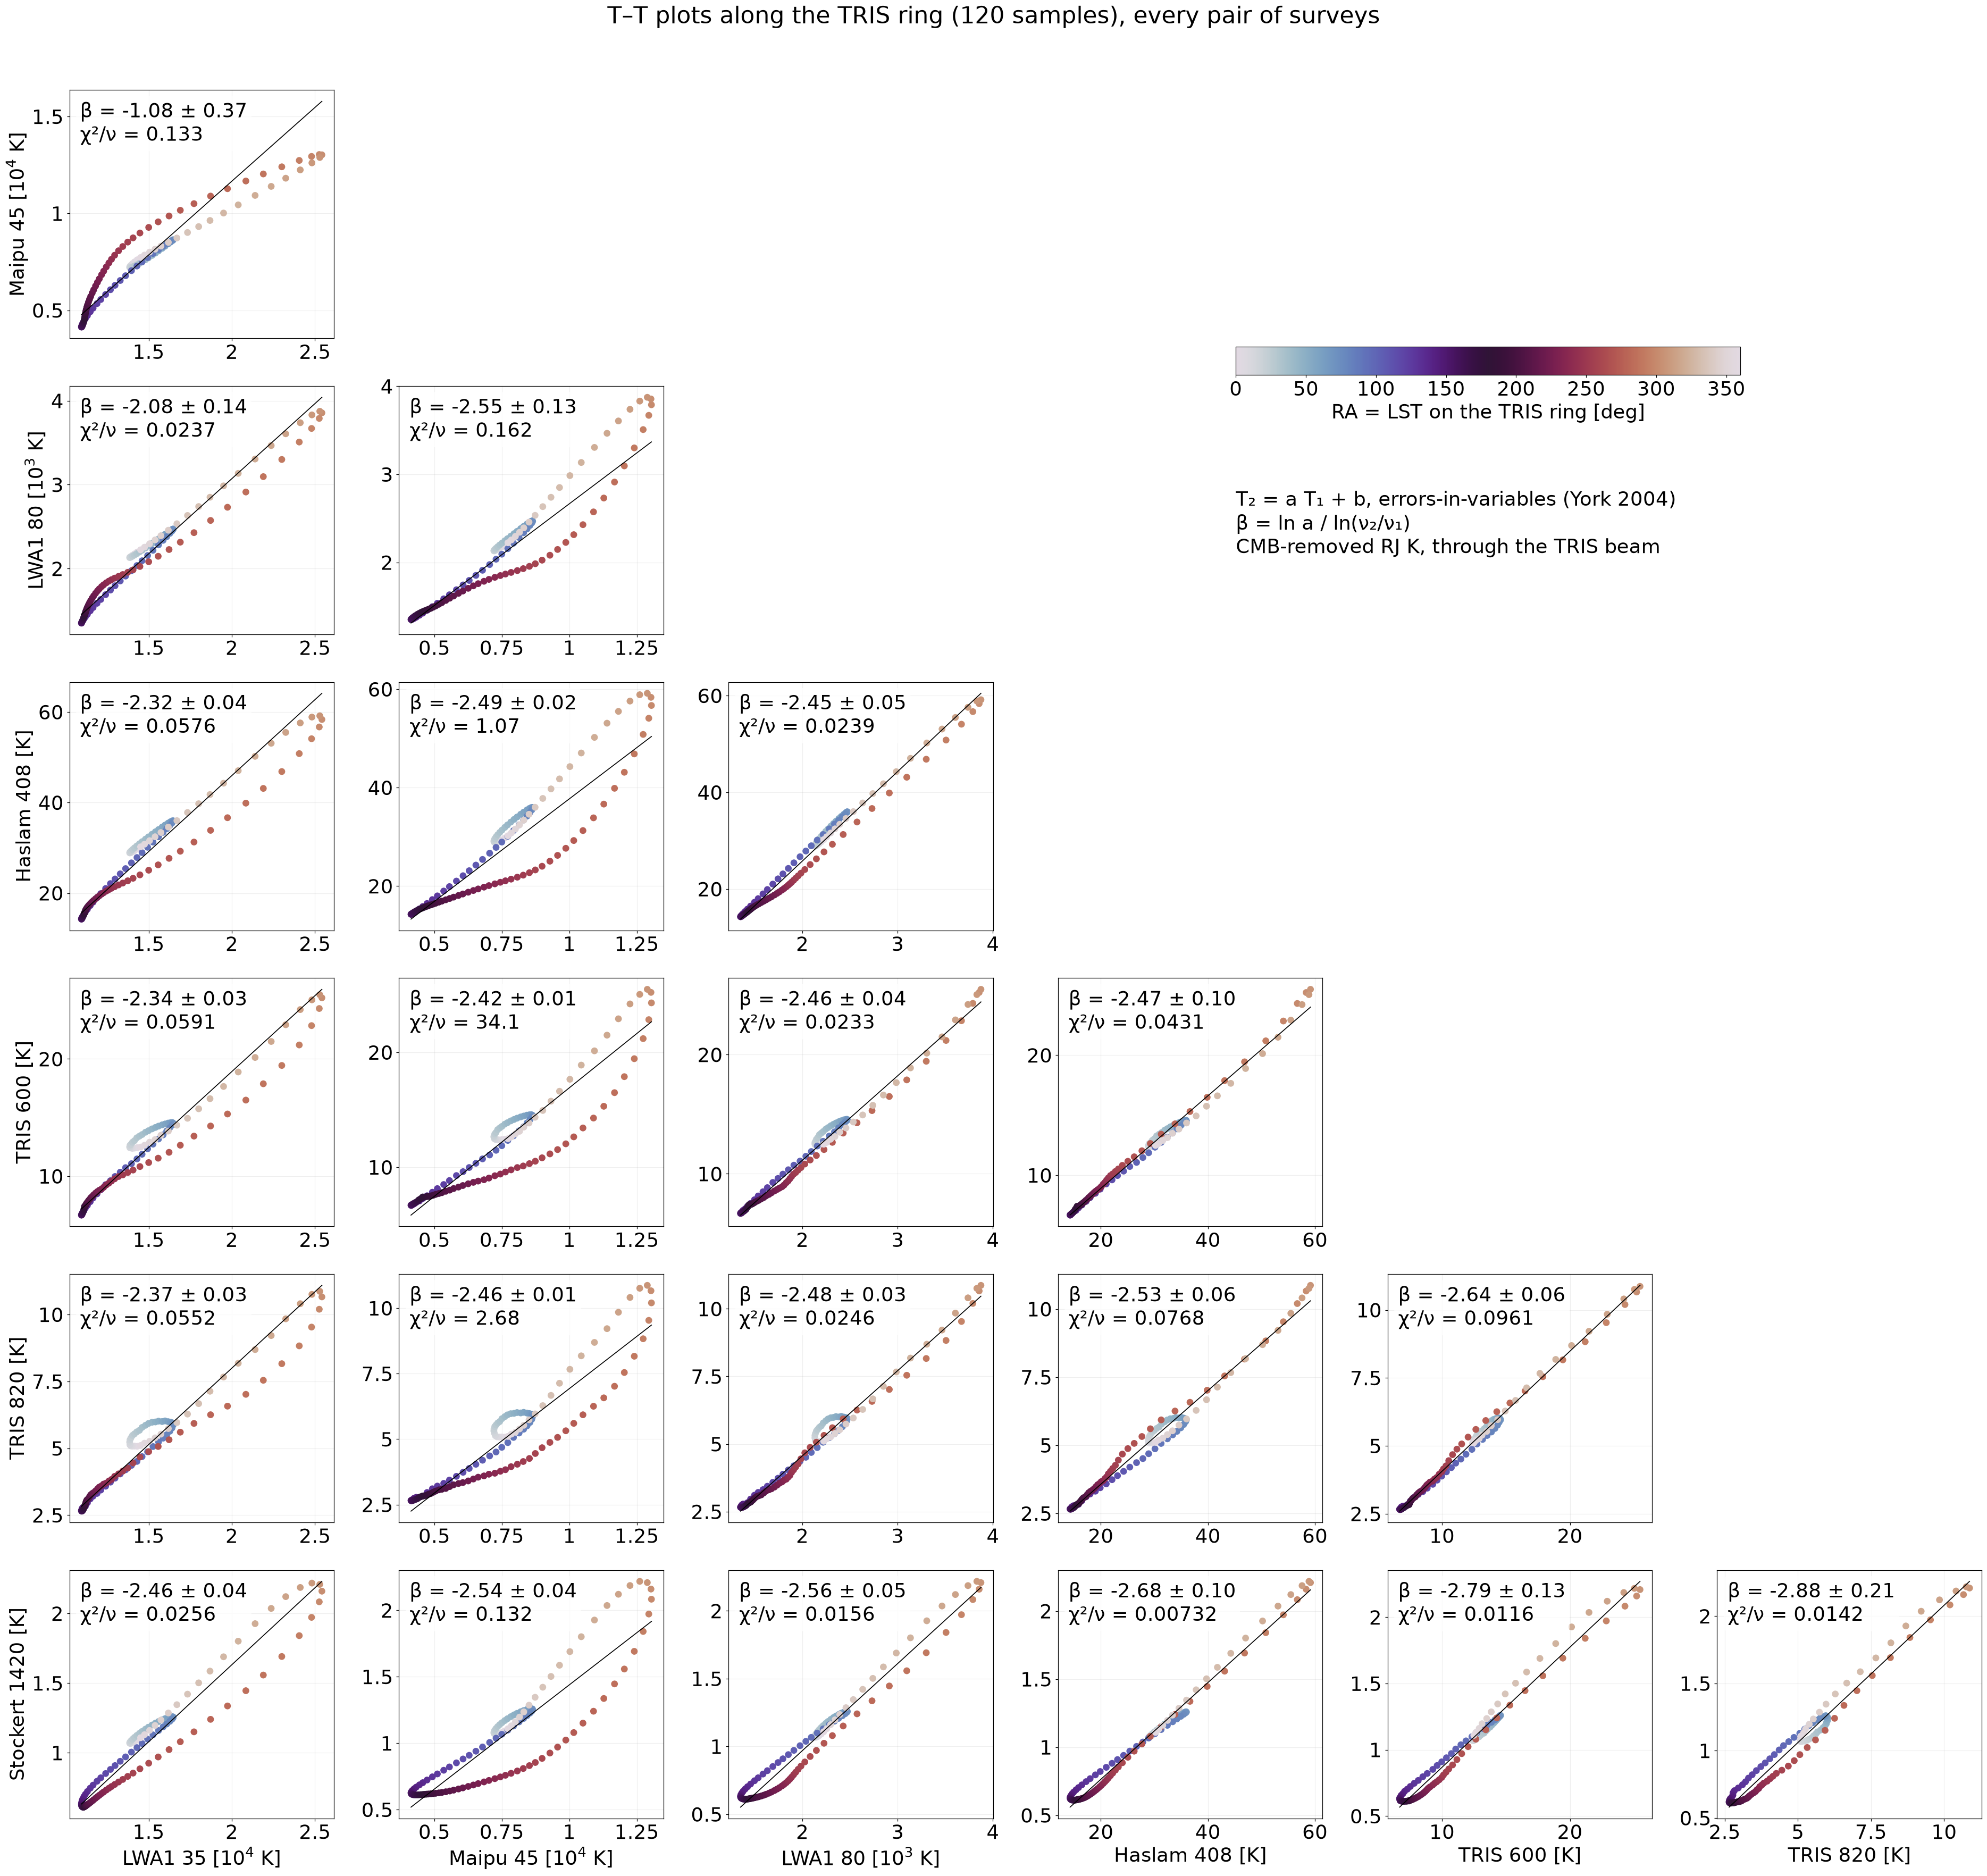

saved model_comparison/phil_plots/plot4_tt_ring_all_pairs.png


In [5]:
n = len(ORDER) - 1                               # rows: ORDER[1:], columns: ORDER[:-1]
fig, axes = plt.subplots(n, n, figsize=(2*2.75 * n + 1.5, 2*2.6 * n + 1.2), squeeze=False)
cmap_ra = plt.get_cmap("twilight")
from matplotlib.ticker import FuncFormatter
# Surveys reaching 10³ K or more: ticks in units of 10^e K, with the power in the axis title.
EXP = {s: (int(np.floor(np.log10(np.nanmax(VALS[s][0])))) if np.nanmax(VALS[s][0]) >= 1e3 else 0) for s in ORDER}
unit = lambda s: f"[10$^{{{EXP[s]}}}$ K]" if EXP[s] else "[K]"
for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        yi, xj = ORDER[i + 1], ORDER[j]
        if j > i:
            ax.axis("off"); continue
        (x, sx), (y, sy) = VALS[xj], VALS[yi]
        ok = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
        sc = ax.scatter(x[ok], y[ok], c=RA[ok], cmap=cmap_ra, vmin=0, vmax=360, s=70, lw=0, zorder=2)
        r = TT_OF.get((xj, yi))
        if r is not None:
            xx = np.linspace(np.nanmin(x[ok]), np.nanmax(x[ok]), 50)
            ax.plot(xx, r["a"] * xx + r["b"], color="black", lw=1.1, zorder=3)
            ax.text(0.04, 0.96, f"β = {r['beta']:.2f} ± {r['err']:.2f}\nχ²/ν = {r['chi2_dof']:.3g}",
                    transform=ax.transAxes, va="top",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
        # ax.tick_params(labelsize=7)              # every panel has its own temperature range
        ax.locator_params(nbins=4)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _, e=EXP[xj]: f"{v / 10 ** e:g}"))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _, e=EXP[yi]: f"{v / 10 ** e:g}"))
        if j == 0:
            ax.set_ylabel(f"{yi} {unit(yi)}")
        if i == n - 1:
            ax.set_xlabel(f"{xj} {unit(xj)}")
        ax.grid(alpha=0.2)
cax = fig.add_axes([0.62, 0.80, 0.25, 0.015])
fig.colorbar(sc, cax=cax, orientation="horizontal", label="RA = LST on the TRIS ring [deg]")
fig.text(0.62, 0.74,
         "T₂ = a T₁ + b, errors-in-variables (York 2004)\n"
         "β = ln a / ln(ν₂/ν₁)\n"
         "CMB-removed RJ K, through the TRIS beam\n"
        #  "⚠ samples 3° apart under a ~20° beam are\n   correlated: β errors are underestimates"
        , va="top")
fig.suptitle("T–T plots along the TRIS ring (120 samples), every pair of surveys", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.985))
save(fig, "plot4_tt_ring_all_pairs")

### Plot 4a — β of every pair against the pair's frequency

Each point is one pair from Plot 4, at the geometric mean of its two frequencies, √(ν₁ν₂) (log axis),
with its errors-in-variables β ± σ_β. Each pair is labelled with its two nominal frequencies in MHz
(35, 80: LWA1; 45: Maipu; 408: Haslam; 600, 820: TRIS; 1420: Stockert). The positions use the TRIS
effective frequencies. Pairs involving Maipu 45 are drawn as open orange squares with orange labels;
the rest are black dots. The dashed line is β = −2.7.

> **⚠ The slopes use all 120 ring samples, which are correlated** (3° apart under a ~20° beam), **so
> the uncertainties are underestimates**, by roughly √(120/18) ≈ 2.6.

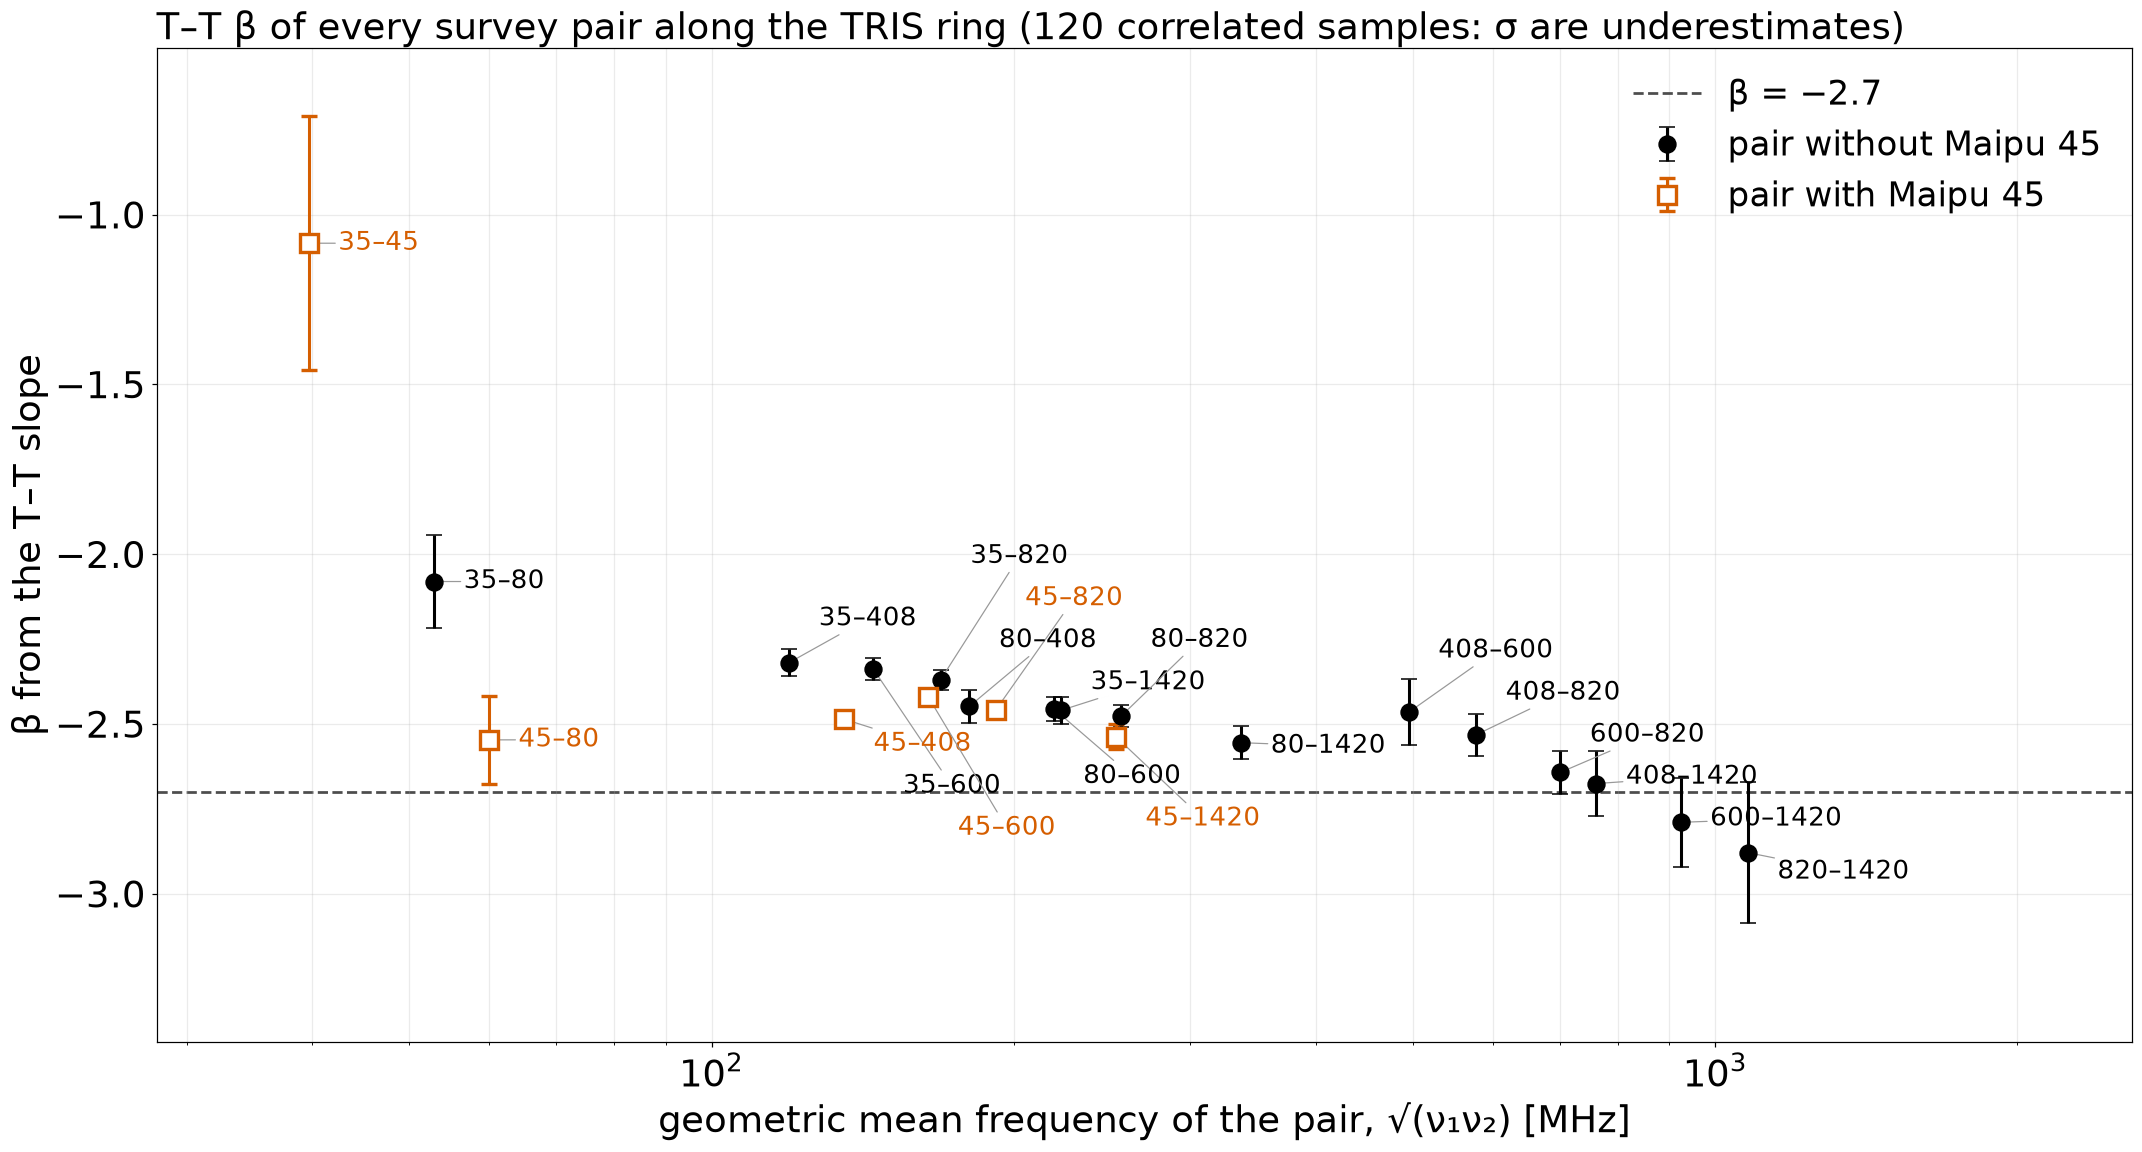

saved model_comparison/phil_plots/plot4a_beta_vs_pair_frequency.png


In [6]:
fig, ax = plt.subplots(figsize=(20, 11))
gm = np.array([np.sqrt(r["nu_lo"] * r["nu_hi"]) for r in TT])
bt = np.array([r["beta"] for r in TT]); er = np.array([r["err"] for r in TT])
is_maipu = np.array(["Maipu 45" in (r["lo"], r["hi"]) for r in TT])
ax.errorbar(gm[~is_maipu], bt[~is_maipu], yerr=er[~is_maipu], fmt="o", ms=11, color="black",
            elinewidth=2, capsize=5, label="pair without Maipu 45", zorder=3)
ax.errorbar(gm[is_maipu], bt[is_maipu], yerr=er[is_maipu], fmt="s", ms=12, mfc="white", mec="#D55E00",
            mew=2.2, color="#D55E00", elinewidth=2, capsize=5, label="pair with Maipu 45", zorder=3)
ax.axhline(-2.7, color="0.3", ls="--", lw=1.8, label="β = −2.7", zorder=1)

# Labels: "ν₁–ν₂" (nominal MHz) next to each point, pushed apart (in axes fraction, log x) from each
# other and from the markers until nothing overlaps.
ax.set_xscale("log")
ax.set_xlim(28, 2600)
ax.set_ylim(np.nanmin(bt - er) - 0.35, np.nanmax(bt + er) + 0.2)
nominal = lambda s: s.split()[-1]
lab = [f"{nominal(r['lo'])}–{nominal(r['hi'])}" for r in TT]
to_ax = lambda x, y: ax.transAxes.inverted().transform(ax.transData.transform((x, y)))
pts = np.array([to_ax(x, y) for x, y in zip(gm, bt)])
pos = pts + np.array([0.015, 0.0])
W, H = 0.075, 0.042                                              # label box size in axes fraction
for _ in range(2000):
    moved = False
    for i in range(len(pos)):
        for j in range(i + 1, len(pos)):                         # label against label
            dx, dy = pos[j] - pos[i]
            if abs(dx) < W and abs(dy) < H:
                s = 1.0 if dy >= 0 else -1.0
                step = 0.5 * (H - abs(dy)) + 1e-3
                pos[j, 1] += s * step; pos[i, 1] -= s * step
                moved = True
        for q in pts:                                            # label against every marker
            dx, dy = q - (pos[i] + [W / 2, 0])
            if abs(dx) < W / 2 + 0.006 and abs(dy) < H / 2 + 0.012:
                s = -1.0 if dy >= 0 else 1.0
                pos[i, 1] += s * (H / 2 + 0.012 - abs(dy) + 1e-3)
                moved = True
    if not moved:
        break
for (px, py), (lx, ly), t, m in zip(pts, pos, lab, is_maipu):
    ax.annotate(t, xy=(px, py), xycoords="axes fraction", xytext=(lx, ly), textcoords="axes fraction",
                fontsize=17, va="center", ha="left", color="#D55E00" if m else "black",
                arrowprops=dict(arrowstyle="-", color="0.6", lw=0.8, shrinkA=0, shrinkB=6))
ax.set_xlabel("geometric mean frequency of the pair, √(ν₁ν₂) [MHz]")
ax.set_ylabel("β from the T–T slope")
ax.grid(alpha=0.25, which="both")
ax.legend(frameon=False, loc="upper right")
ax.set_title("T–T β of every survey pair along the TRIS ring (120 correlated samples: σ are underestimates)",
             loc="left")
fig.tight_layout()
save(fig, "plot4a_beta_vs_pair_frequency")

### Plot 4c — β of every pair against its mean frequency, with the frequency span

The same β ± σ_β as Plot 4a, at the geometric mean of the pair's two frequencies, √(ν₁ν₂) (log axis). The
**horizontal bar runs from ν₁ to ν₂**, so its two ends show which surveys the pair is made of; the tick marks
on the x axis are the survey frequencies. Pairs involving Maipu 45 are open orange squares, the rest black
dots; the dashed line is β = −2.7.

> **⚠ The slopes use all 120 correlated ring samples, so the vertical uncertainties are underestimates.**

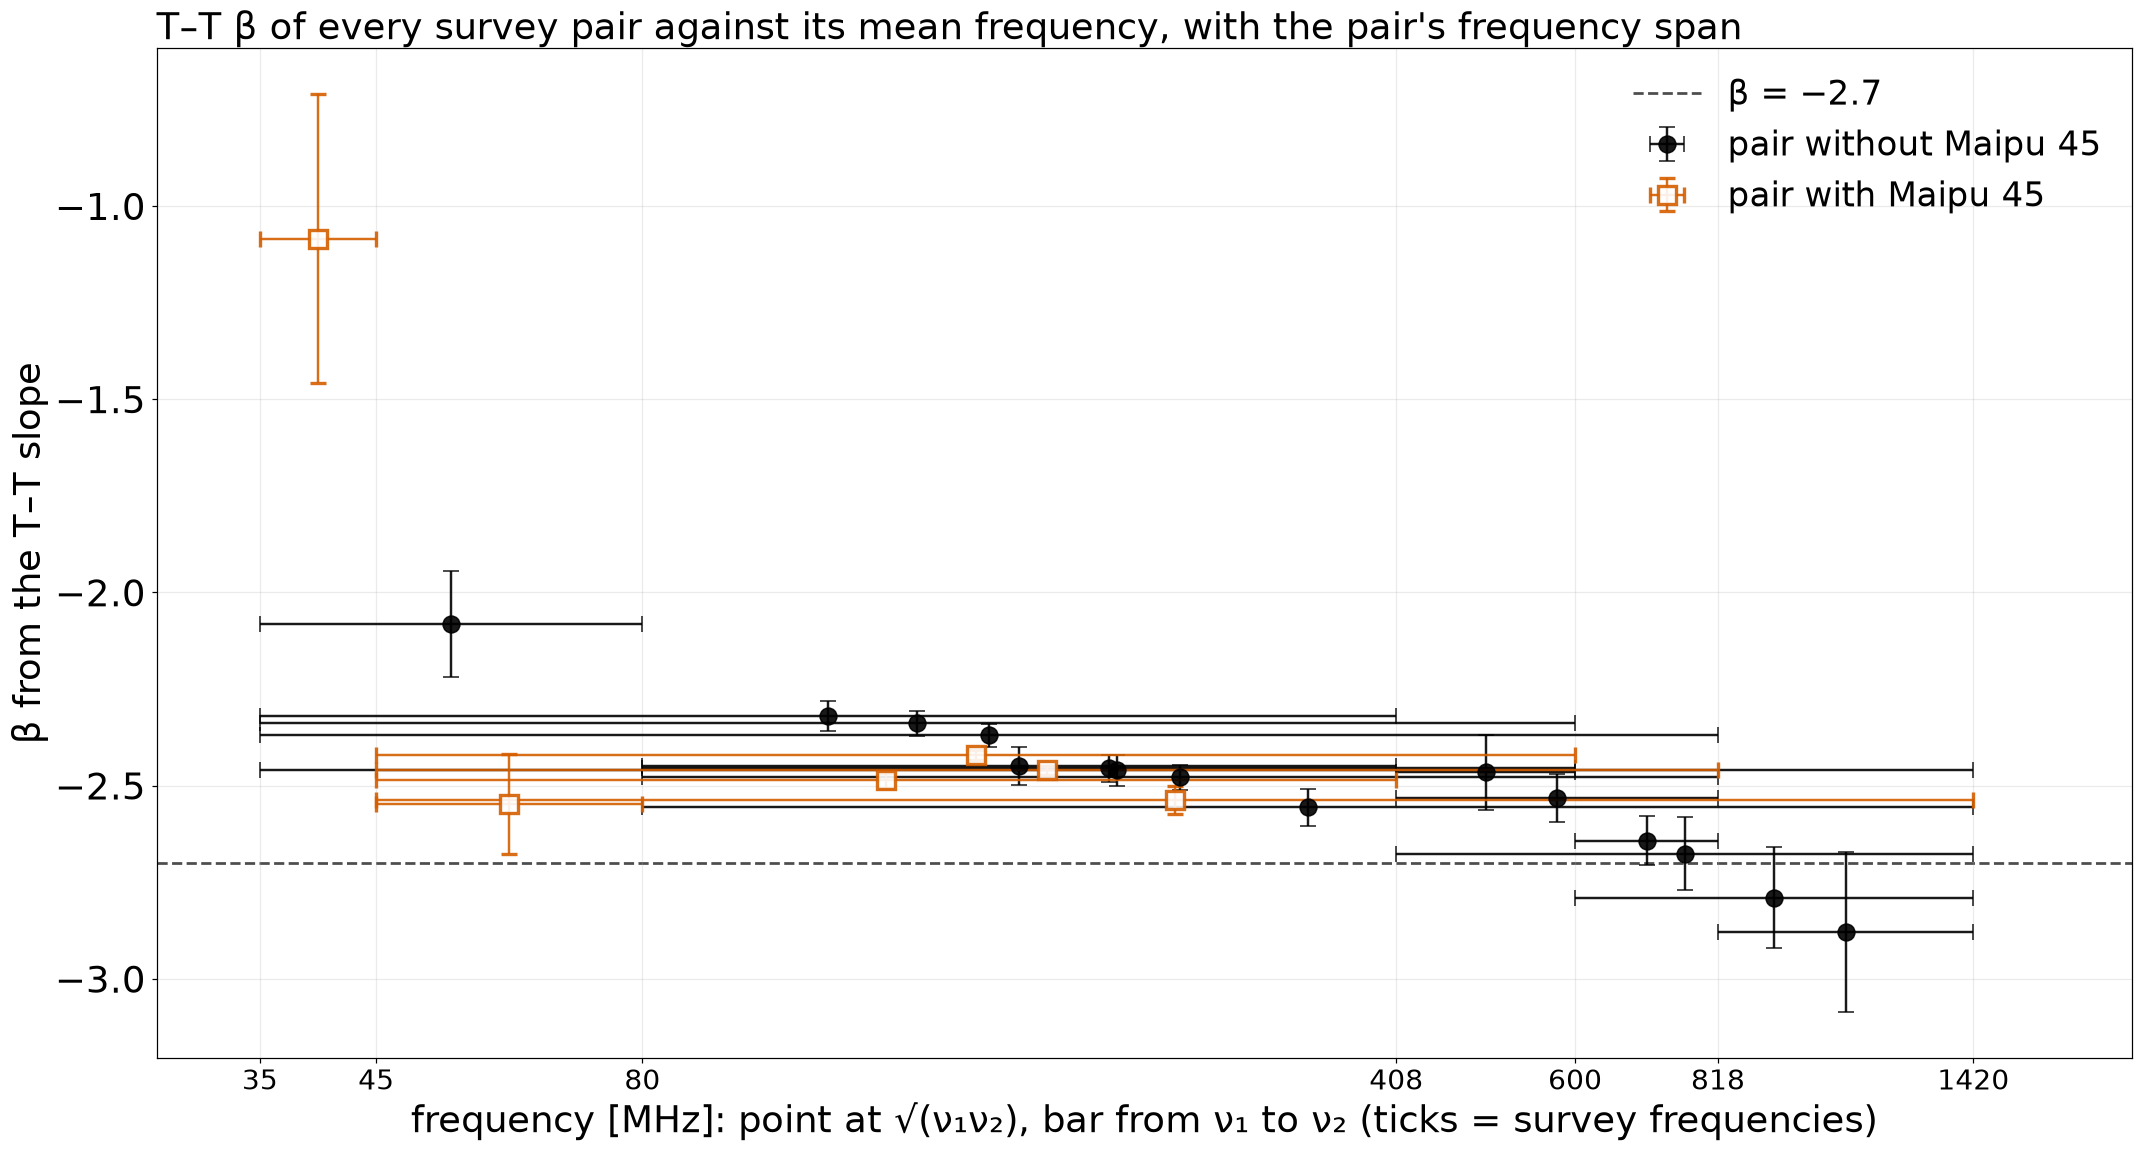

saved model_comparison/phil_plots/plot4c_beta_vs_mean_frequency_span.png


In [7]:
fig, ax = plt.subplots(figsize=(20, 11))
lo_f = np.array([r["nu_lo"] for r in TT]); hi_f = np.array([r["nu_hi"] for r in TT])
gm = np.sqrt(lo_f * hi_f)
bt = np.array([r["beta"] for r in TT]); er = np.array([r["err"] for r in TT])
is_maipu = np.array(["Maipu 45" in (r["lo"], r["hi"]) for r in TT])
xerr = np.vstack([gm - lo_f, hi_f - gm])
for sel, kw in ((~is_maipu, dict(fmt="o", ms=11, color="black", label="pair without Maipu 45")),
                (is_maipu, dict(fmt="s", ms=12, mfc="white", mec="#D55E00", mew=2.2, color="#D55E00",
                                label="pair with Maipu 45"))):
    ax.errorbar(gm[sel], bt[sel], yerr=er[sel], xerr=xerr[:, sel], elinewidth=1.6, capsize=5, zorder=3,
                alpha=0.9, **kw)
ax.axhline(-2.7, color="0.3", ls="--", lw=1.8, label="β = −2.7", zorder=1)
ax.set_xscale("log")
ax.set_xlim(28, 2000)
ax.set_xticks([FREQ_L[n] for n in ORDER])
ax.set_xticklabels([f"{FREQ_L[n]:.0f}" for n in ORDER], fontsize=18)
ax.minorticks_off()
ax.set_xlabel("frequency [MHz]: point at √(ν₁ν₂), bar from ν₁ to ν₂ (ticks = survey frequencies)")
ax.set_ylabel("β from the T–T slope")
ax.grid(alpha=0.25)
ax.legend(frameon=False, loc="upper right")
ax.set_title("T–T β of every survey pair against its mean frequency, with the pair's frequency span", loc="left")
fig.tight_layout()
save(fig, "plot4c_beta_vs_mean_frequency_span")

### Plot 4b — the same fits, ring split at RA = 200°

Plot 4 shows two branches in many pairs, so one slope over the whole ring may average two different
spectral indices. Here every pair is refitted with the same `tt_betas`: the same errors-in-variables
fit, with the same √(χ²/ν) inflation. The fit is done separately for the 67 samples with RA < 200°
and the 53 with RA > 200° (no sample lies at exactly 200°). Each matrix is laid out like Plot 5's
left panel: β ± σ_β below the diagonal, χ²/ν above. Both share one colour scale (the 2nd–98th
percentile of the β in the two halves; LWA1 35 vs Maipu 45 is past its end), so a cell whose colour
changes between the halves shows where the index depends on position.
`plot4b_tt_betas_ra_split.csv` lists, for every pair, the whole-ring β, the β in each half, their
difference (RA > 200° minus RA < 200°) and that difference divided by the two σ added in quadrature.

> **⚠ The samples within each half are still correlated, so these uncertainties are underestimates too.**

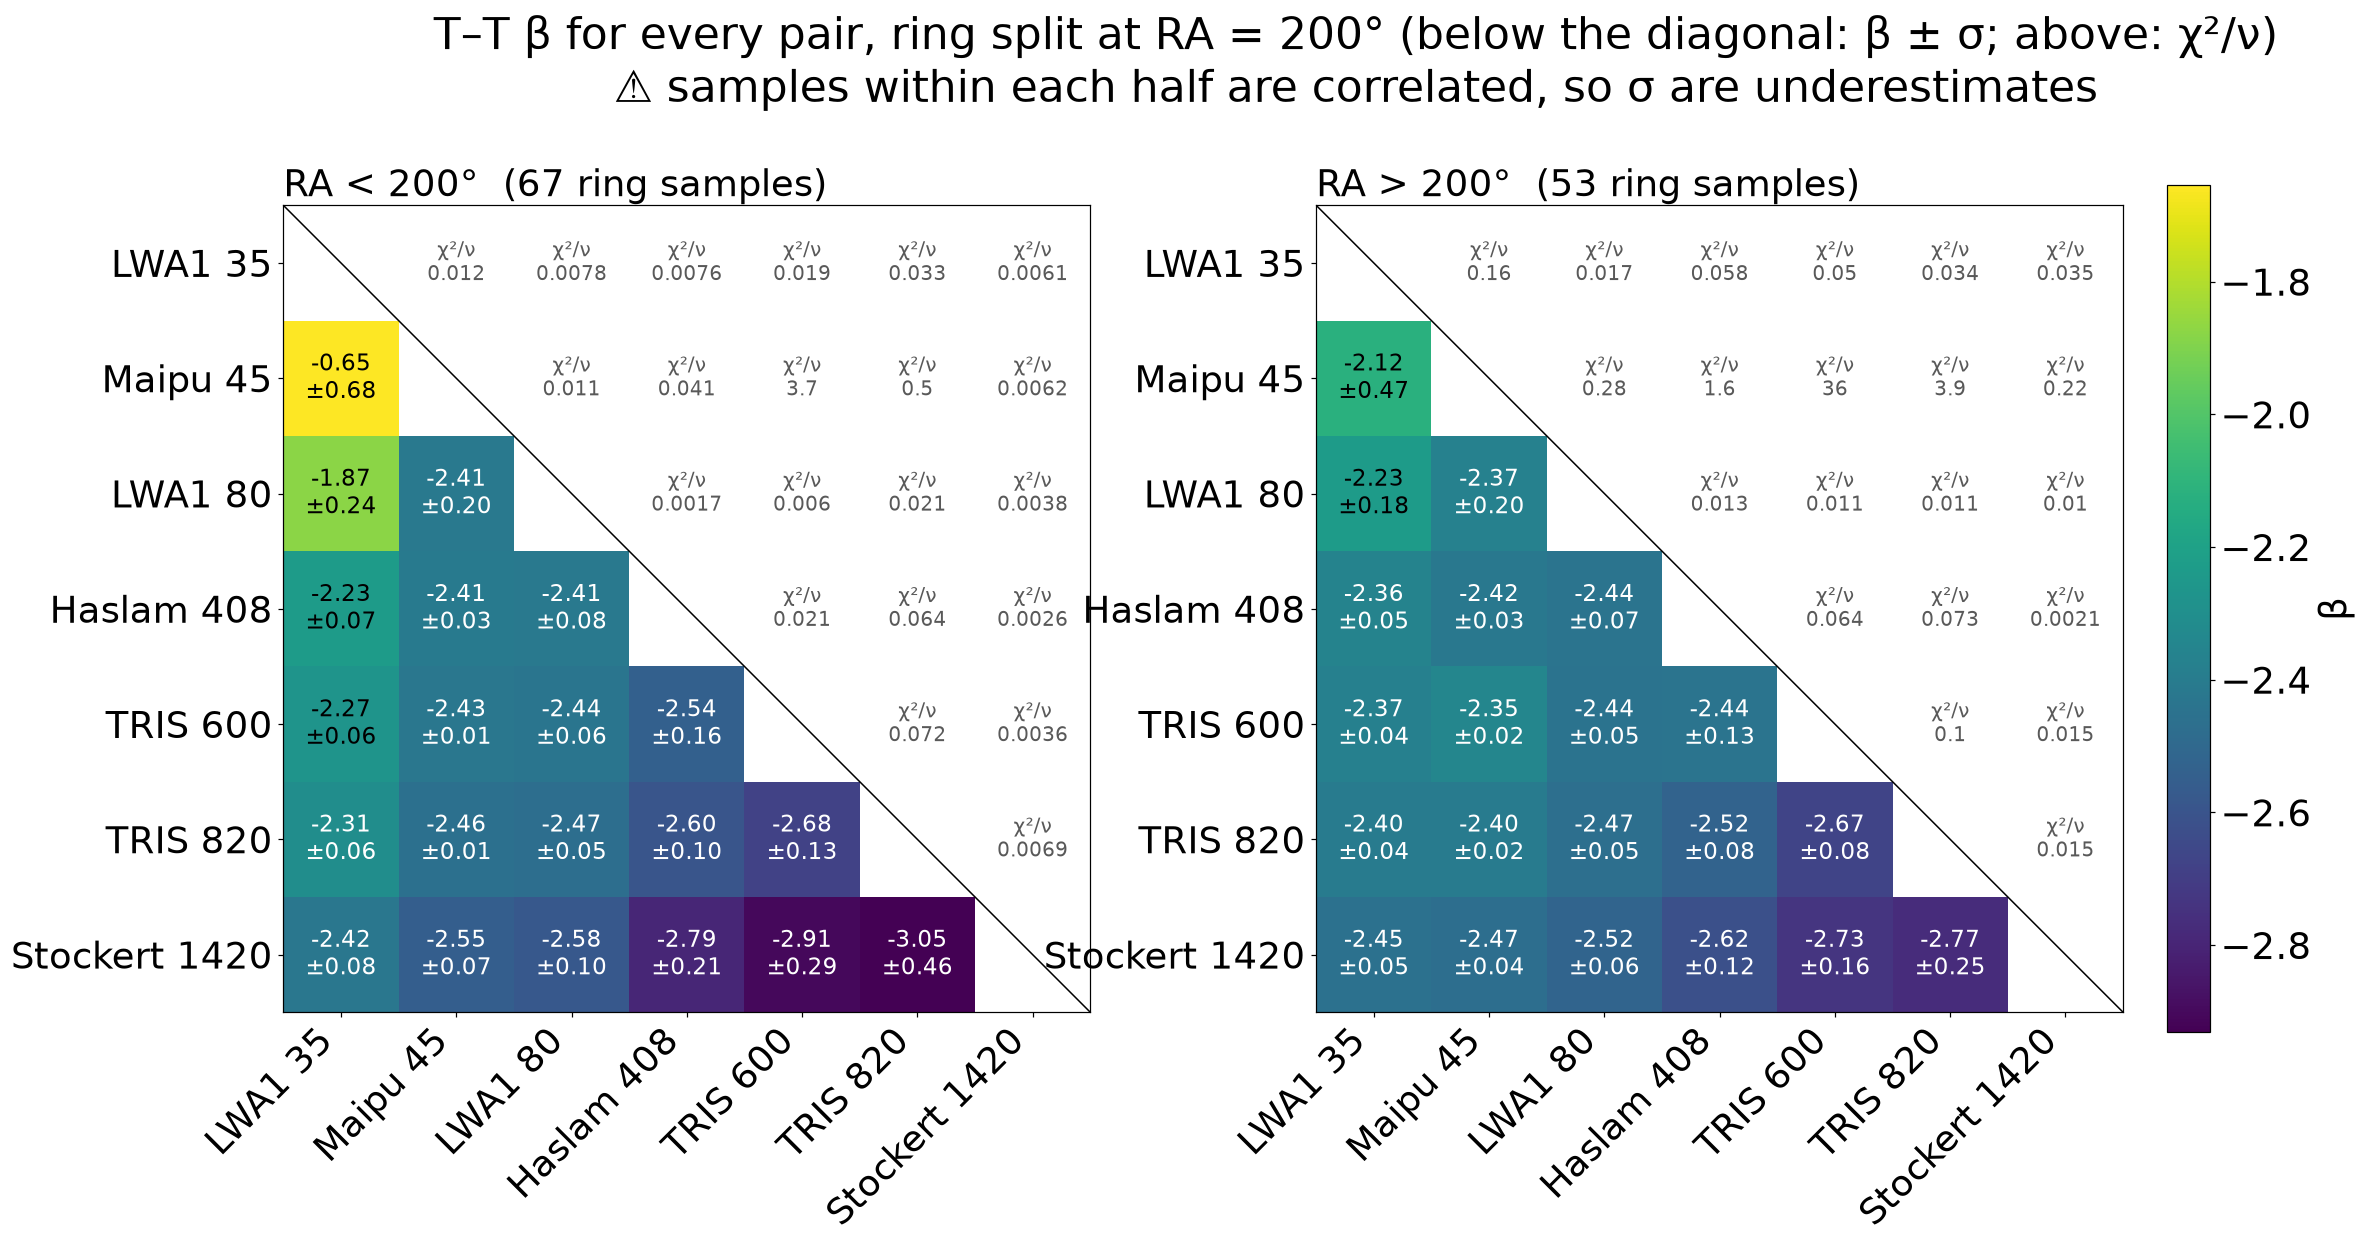

saved model_comparison/phil_plots/plot4b_beta_matrix_ra_split.png
saved model_comparison/phil_plots/plot4b_tt_betas_ra_split.csv

  survey 1      survey 2  β all  σ all  β RA < 200°  σ RA < 200°  β RA > 200°  σ RA > 200°  β(RA>200) − β(RA<200)  difference / combined σ
   LWA1 35      Maipu 45 -1.085  0.374       -0.655        0.676       -2.121        0.469                 -1.466                   -1.782
   LWA1 35       LWA1 80 -2.081  0.137       -1.874        0.245       -2.229        0.185                 -0.355                   -1.156
   LWA1 35    Haslam 408 -2.320  0.040       -2.232        0.073       -2.362        0.051                 -0.130                   -1.469
   LWA1 35      TRIS 600 -2.339  0.032       -2.269        0.060       -2.375        0.040                 -0.106                   -1.463
   LWA1 35      TRIS 820 -2.370  0.029       -2.305        0.056       -2.401        0.037                 -0.096                   -1.420
   LWA1 35 Stockert 1420 -2.460  0.0

In [8]:
from matplotlib.colors import Normalize
RA_SPLIT = 200.0
HALVES = {f"RA < {RA_SPLIT:g}°": RA < RA_SPLIT, f"RA > {RA_SPLIT:g}°": RA > RA_SPLIT}
TT_H = {}
for h, sel in HALVES.items():
    vals_h = {s: (np.where(sel, t, np.nan), np.where(sel, e, np.nan)) for s, (t, e) in VALS.items()}
    TT_H[h] = {(r["lo"], r["hi"]): r for r in tt_betas(vals_h, FREQ_L)}

NS = len(ORDER)
MAT = {h: np.full((NS, NS), np.nan) for h in HALVES}; ERR = {h: m.copy() for h, m in MAT.items()}
CHI2 = {h: m.copy() for h, m in MAT.items()}
for h in HALVES:
    for i, lo in enumerate(ORDER):
        for j in range(i + 1, NS):
            r = TT_H[h].get((lo, ORDER[j]))
            if r is not None:
                MAT[h][j, i], ERR[h][j, i], CHI2[h][i, j] = r["beta"], r["err"], r["chi2_dof"]

allb = np.concatenate([m[np.isfinite(m)] for m in MAT.values()])
lo_b, hi_b = np.percentile(allb, [2, 98])
norm = Normalize(lo_b, hi_b)
cmap_b = plt.get_cmap("viridis").copy(); cmap_b.set_bad("white")
fig, axs = plt.subplots(1, 2, figsize=(26, 12.5), gridspec_kw=dict(wspace=0.28))
for ax, h in zip(axs, HALVES):
    im = ax.imshow(MAT[h], cmap=cmap_b, norm=norm)
    for i in range(NS):
        for j in range(NS):
            if i > j and np.isfinite(MAT[h][i, j]):
                v = MAT[h][i, j]
                ax.text(j, i, f"{v:.2f}\n±{ERR[h][i, j]:.2f}", ha="center", va="center", fontsize=15,
                        color="white" if v < (lo_b + hi_b) / 2 else "black")
            elif i < j and np.isfinite(CHI2[h][i, j]):
                ax.text(j, i, f"χ²/ν\n{CHI2[h][i, j]:.2g}", ha="center", va="center", fontsize=13, color="0.35")
    ax.plot([-0.5, NS - 0.5], [-0.5, NS - 0.5], color="k", lw=1)
    ax.set_xticks(range(NS)); ax.set_yticks(range(NS))
    ax.set_xticklabels(ORDER, rotation=45, ha="right"); ax.set_yticklabels(ORDER)
    n_h = int(HALVES[h].sum())
    ax.set_title(f"{h}  ({n_h} ring samples)", loc="left")
fig.colorbar(im, ax=list(axs), shrink=0.8, pad=0.02, label="β")
fig.suptitle("T–T β for every pair, ring split at RA = 200° (below the diagonal: β ± σ; above: χ²/ν)\n"
             "⚠ samples within each half are correlated, so σ are underestimates", y=0.93)
save(fig, "plot4b_beta_matrix_ra_split")

lo_h, hi_h = HALVES
rows = []
for r in TT:
    p = (r["lo"], r["hi"]); a, b = TT_H[lo_h].get(p), TT_H[hi_h].get(p)
    rows.append({"survey 1": p[0], "survey 2": p[1], "β all": r["beta"], "σ all": r["err"],
                 f"β {lo_h}": a["beta"] if a else np.nan, f"σ {lo_h}": a["err"] if a else np.nan,
                 f"β {hi_h}": b["beta"] if b else np.nan, f"σ {hi_h}": b["err"] if b else np.nan})
split = pd.DataFrame(rows)
split["β(RA>200) − β(RA<200)"] = split[f"β {hi_h}"] - split[f"β {lo_h}"]
split["difference / combined σ"] = split["β(RA>200) − β(RA<200)"] / np.hypot(split[f"σ {lo_h}"], split[f"σ {hi_h}"])
split.to_csv(OUT_DIR / "plot4b_tt_betas_ra_split.csv", index=False)
print(f"saved {(OUT_DIR / 'plot4b_tt_betas_ra_split.csv').relative_to(REPO)}\n")
with pd.option_context("display.width", 250):
    print(split.round(3).to_string(index=False))

### Plots 4d–4f — the same β without the Maipu or RA splits

The β of Plots 4a, 4c and 4b drawn without separating anything: **4d** is Plot 4a with every pair as the same black
dot (labelled ν₁–ν₂, pairs with Maipu 45 not set apart), **4e** is Plot 4c the same way (point at √(ν₁ν₂), bar from
ν₁ to ν₂), and **4f** is a single β matrix fitted over the **whole ring** (all 120 samples, no RA = 200° split; β ± σ
below the diagonal, χ²/ν above). The numbers are the same fits as `plot4_tt_betas_data.csv`.

> **⚠ The slopes use all 120 correlated ring samples, so the uncertainties are underestimates.**

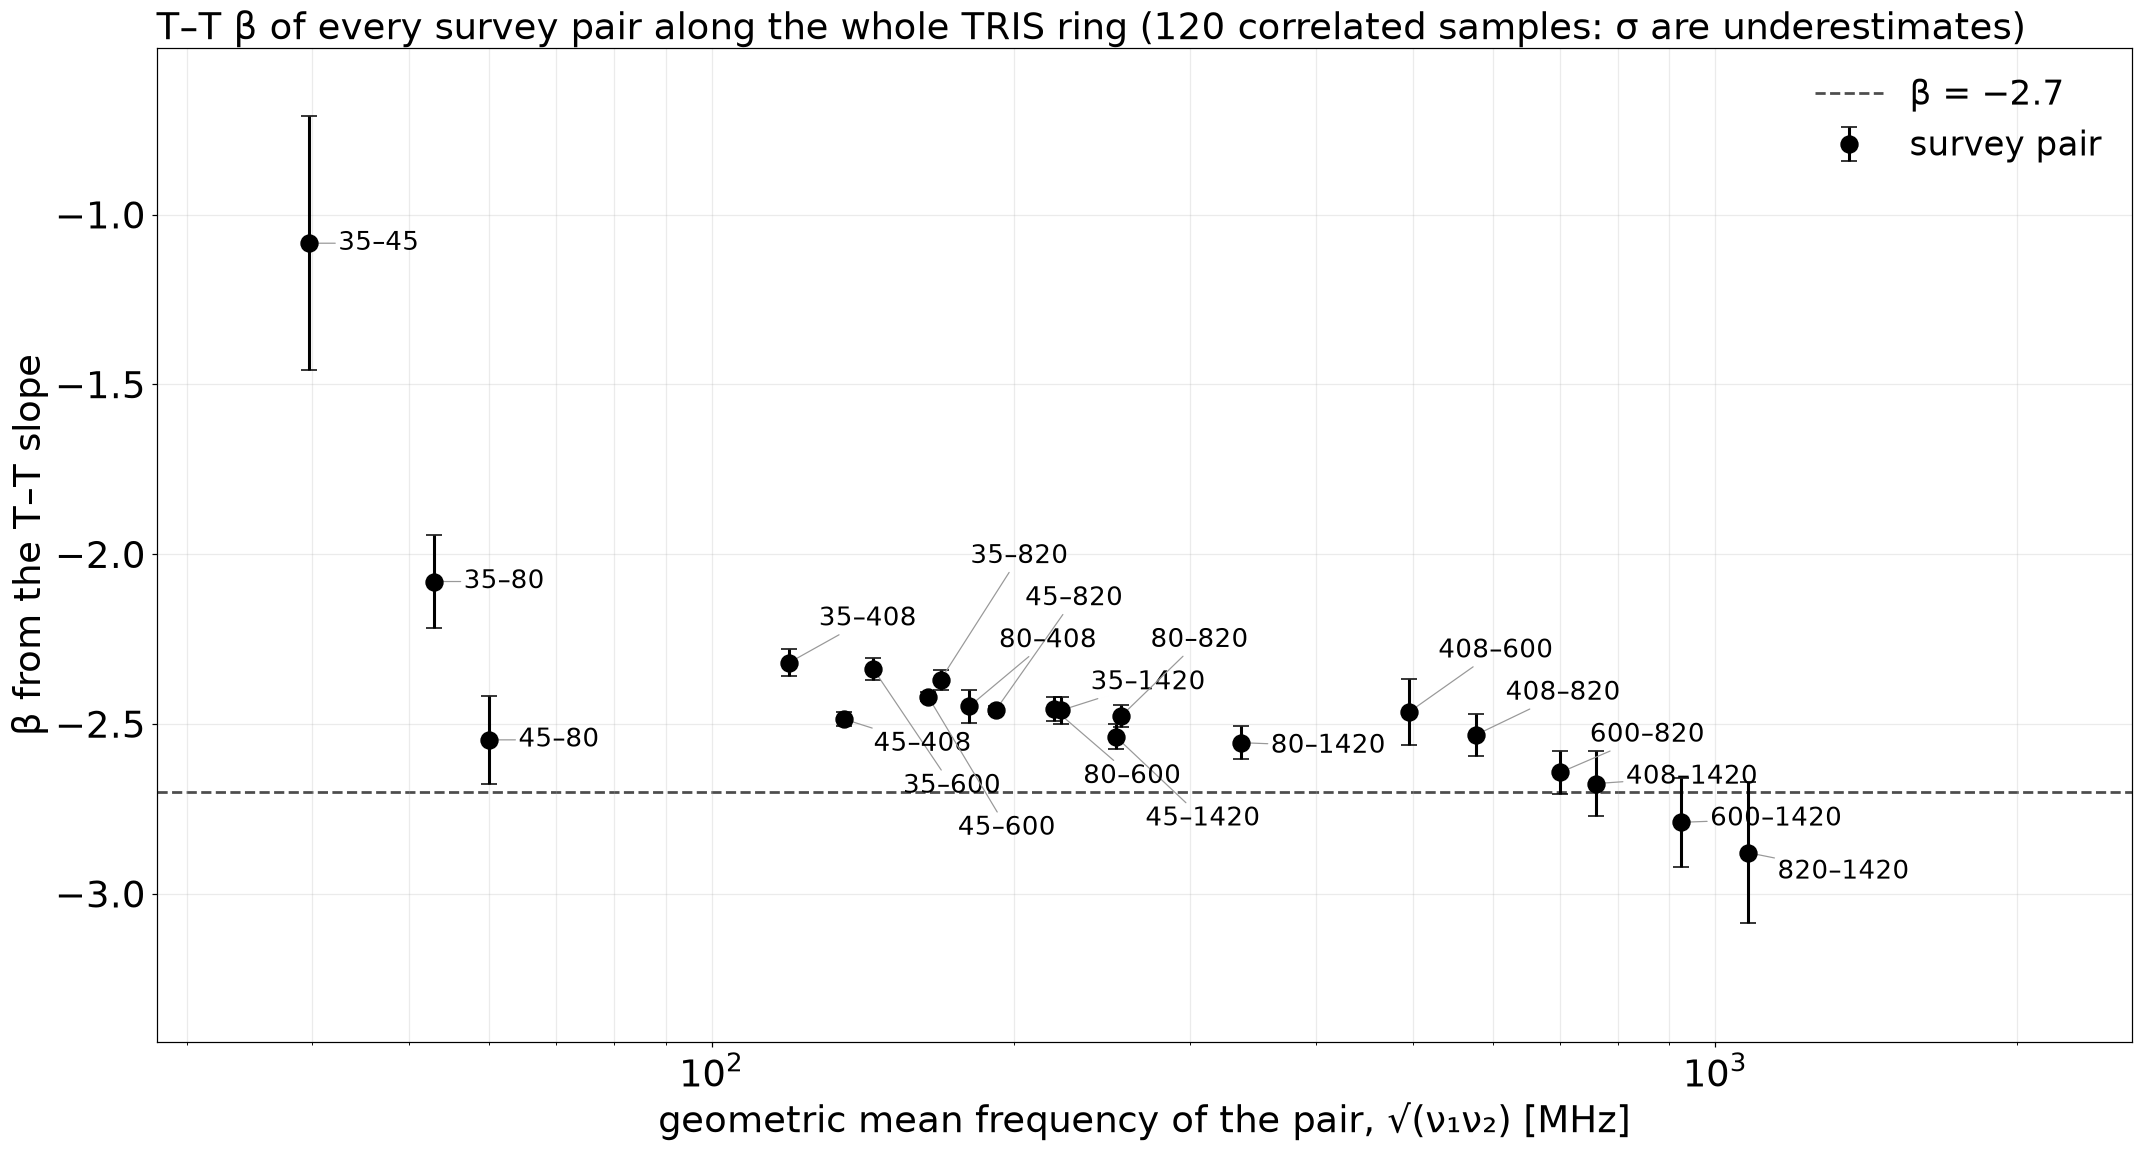

saved model_comparison/phil_plots/plot4d_beta_vs_pair_frequency_all_pairs.png


In [9]:
fig, ax = plt.subplots(figsize=(20, 11))
gm = np.array([np.sqrt(r["nu_lo"] * r["nu_hi"]) for r in TT])
bt = np.array([r["beta"] for r in TT]); er = np.array([r["err"] for r in TT])
ax.errorbar(gm, bt, yerr=er, fmt="o", ms=11, color="black", elinewidth=2, capsize=5, label="survey pair", zorder=3)
ax.axhline(-2.7, color="0.3", ls="--", lw=1.8, label="β = −2.7", zorder=1)

# Labels: "ν₁–ν₂" (nominal MHz) next to each point, pushed apart (in axes fraction, log x) from each
# other and from the markers until nothing overlaps.
ax.set_xscale("log")
ax.set_xlim(28, 2600)
ax.set_ylim(np.nanmin(bt - er) - 0.35, np.nanmax(bt + er) + 0.2)
nominal = lambda s: s.split()[-1]
lab = [f"{nominal(r['lo'])}–{nominal(r['hi'])}" for r in TT]
to_ax = lambda x, y: ax.transAxes.inverted().transform(ax.transData.transform((x, y)))
pts = np.array([to_ax(x, y) for x, y in zip(gm, bt)])
pos = pts + np.array([0.015, 0.0])
W, H = 0.075, 0.042                                              # label box size in axes fraction
for _ in range(2000):
    moved = False
    for i in range(len(pos)):
        for j in range(i + 1, len(pos)):                         # label against label
            dx, dy = pos[j] - pos[i]
            if abs(dx) < W and abs(dy) < H:
                s = 1.0 if dy >= 0 else -1.0
                step = 0.5 * (H - abs(dy)) + 1e-3
                pos[j, 1] += s * step; pos[i, 1] -= s * step
                moved = True
        for q in pts:                                            # label against every marker
            dx, dy = q - (pos[i] + [W / 2, 0])
            if abs(dx) < W / 2 + 0.006 and abs(dy) < H / 2 + 0.012:
                s = -1.0 if dy >= 0 else 1.0
                pos[i, 1] += s * (H / 2 + 0.012 - abs(dy) + 1e-3)
                moved = True
    if not moved:
        break
for (px, py), (lx, ly), t in zip(pts, pos, lab):
    ax.annotate(t, xy=(px, py), xycoords="axes fraction", xytext=(lx, ly), textcoords="axes fraction",
                fontsize=17, va="center", ha="left", color="black",
                arrowprops=dict(arrowstyle="-", color="0.6", lw=0.8, shrinkA=0, shrinkB=6))
ax.set_xlabel("geometric mean frequency of the pair, √(ν₁ν₂) [MHz]")
ax.set_ylabel("β from the T–T slope")
ax.grid(alpha=0.25, which="both")
ax.legend(frameon=False, loc="upper right")
ax.set_title("T–T β of every survey pair along the whole TRIS ring (120 correlated samples: σ are underestimates)",
             loc="left")
fig.tight_layout()
save(fig, "plot4d_beta_vs_pair_frequency_all_pairs")

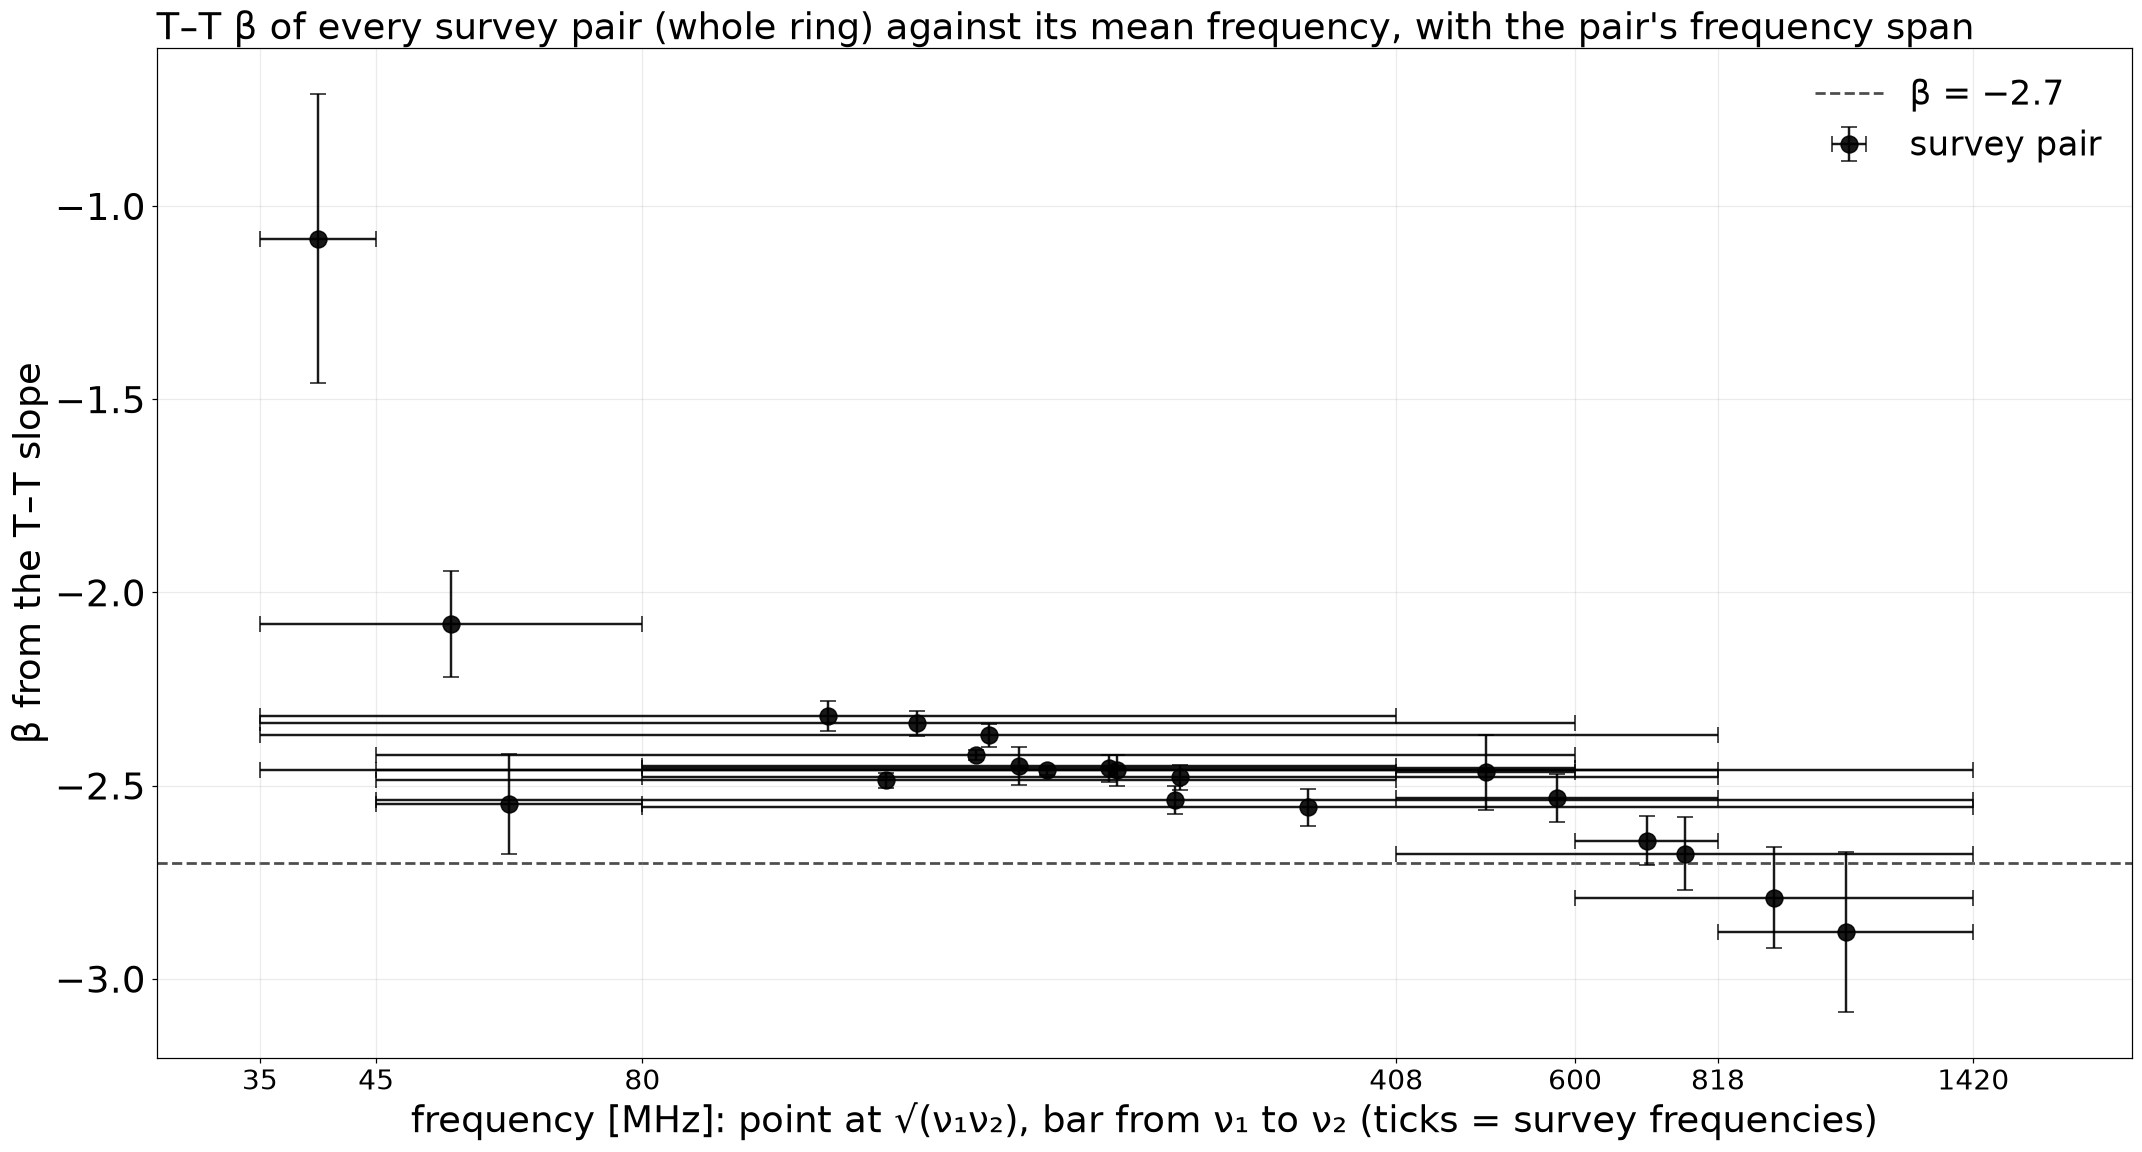

saved model_comparison/phil_plots/plot4e_beta_vs_mean_frequency_span_all_pairs.png


In [10]:
fig, ax = plt.subplots(figsize=(20, 11))
lo_f = np.array([r["nu_lo"] for r in TT]); hi_f = np.array([r["nu_hi"] for r in TT])
gm = np.sqrt(lo_f * hi_f)
bt = np.array([r["beta"] for r in TT]); er = np.array([r["err"] for r in TT])
xerr = np.vstack([gm - lo_f, hi_f - gm])
ax.errorbar(gm, bt, yerr=er, xerr=xerr, fmt="o", ms=11, color="black", elinewidth=1.6, capsize=5, zorder=3,
            alpha=0.9, label="survey pair")
ax.axhline(-2.7, color="0.3", ls="--", lw=1.8, label="β = −2.7", zorder=1)
ax.set_xscale("log")
ax.set_xlim(28, 2000)
ax.set_xticks([FREQ_L[n] for n in ORDER])
ax.set_xticklabels([f"{FREQ_L[n]:.0f}" for n in ORDER], fontsize=18)
ax.minorticks_off()
ax.set_xlabel("frequency [MHz]: point at √(ν₁ν₂), bar from ν₁ to ν₂ (ticks = survey frequencies)")
ax.set_ylabel("β from the T–T slope")
ax.grid(alpha=0.25)
ax.legend(frameon=False, loc="upper right")
ax.set_title("T–T β of every survey pair (whole ring) against its mean frequency, with the pair's frequency span", loc="left")
fig.tight_layout()
save(fig, "plot4e_beta_vs_mean_frequency_span_all_pairs")

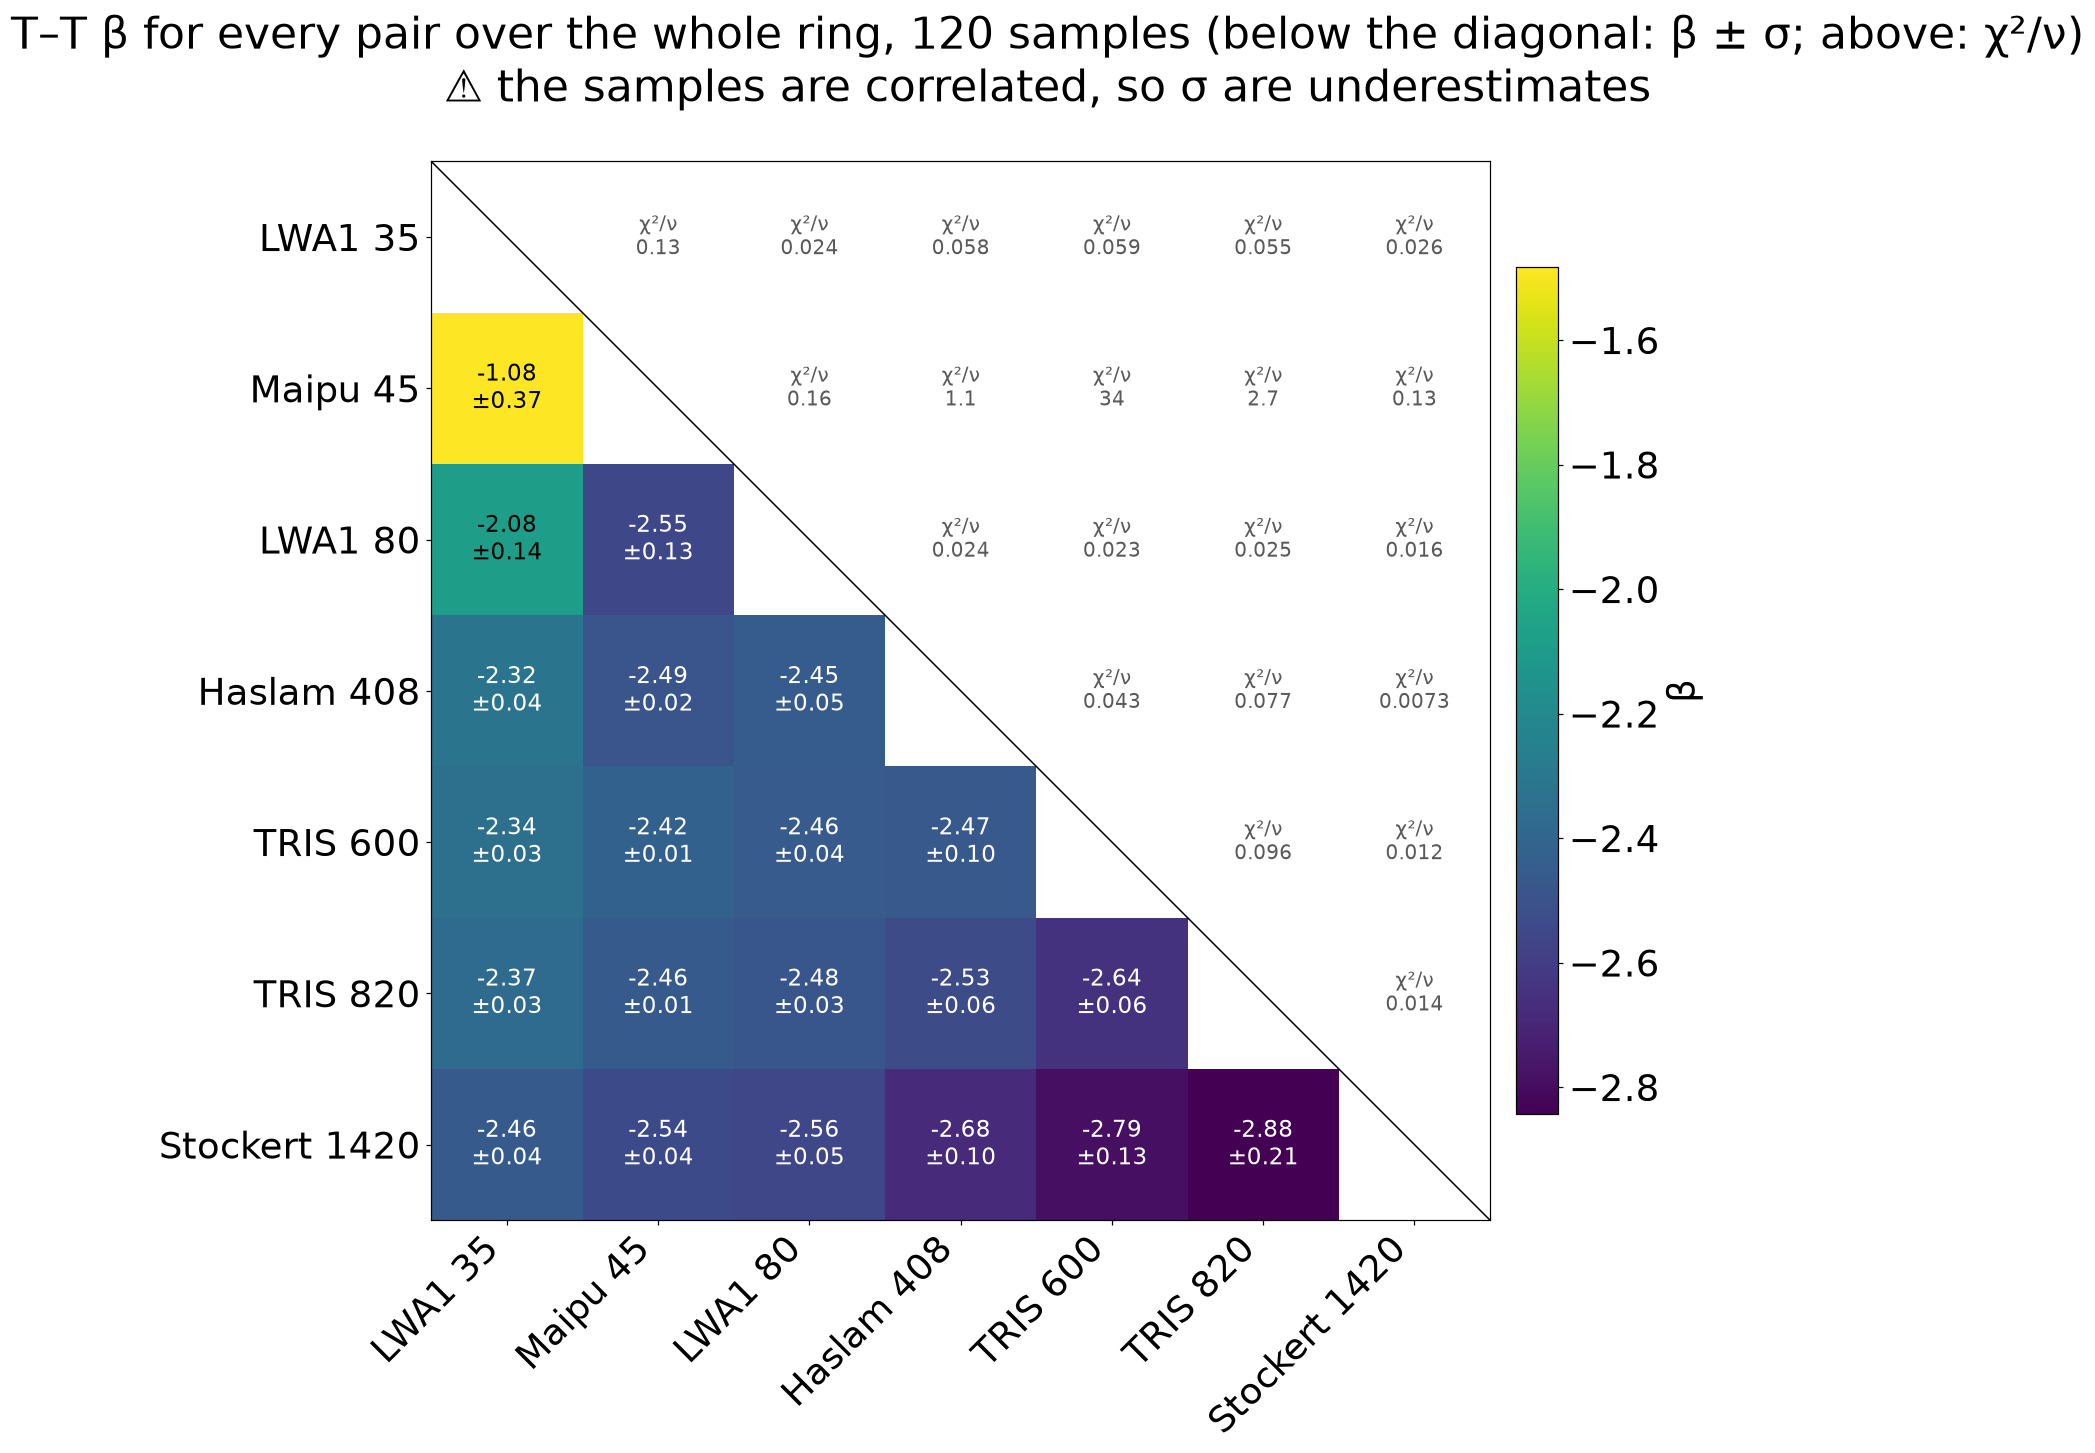

saved model_comparison/phil_plots/plot4f_beta_matrix_whole_ring.png


In [11]:
from matplotlib.colors import Normalize
NS = len(ORDER)
MAT_W, ERR_W, CHI2_W = (np.full((NS, NS), np.nan) for _ in range(3))
for i, lo in enumerate(ORDER):
    for j in range(i + 1, NS):
        r = TT_OF.get((lo, ORDER[j]))
        if r is not None:
            MAT_W[j, i], ERR_W[j, i], CHI2_W[i, j] = r["beta"], r["err"], r["chi2_dof"]
lo_w, hi_w = np.percentile(MAT_W[np.isfinite(MAT_W)], [2, 98])
cmap_w = plt.get_cmap("viridis").copy(); cmap_w.set_bad("white")
fig, ax = plt.subplots(figsize=(15, 12.5))
im = ax.imshow(MAT_W, cmap=cmap_w, norm=Normalize(lo_w, hi_w))
for i in range(NS):
    for j in range(NS):
        if i > j and np.isfinite(MAT_W[i, j]):
            v = MAT_W[i, j]
            ax.text(j, i, f"{v:.2f}\n±{ERR_W[i, j]:.2f}", ha="center", va="center", fontsize=15,
                    color="white" if v < (lo_w + hi_w) / 2 else "black")
        elif i < j and np.isfinite(CHI2_W[i, j]):
            ax.text(j, i, f"χ²/ν\n{CHI2_W[i, j]:.2g}", ha="center", va="center", fontsize=13, color="0.35")
ax.plot([-0.5, NS - 0.5], [-0.5, NS - 0.5], color="k", lw=1)
ax.set_xticks(range(NS)); ax.set_yticks(range(NS))
ax.set_xticklabels(ORDER, rotation=45, ha="right"); ax.set_yticklabels(ORDER)
fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02, label="β")
fig.suptitle(f"T–T β for every pair over the whole ring, {N} samples (below the diagonal: β ± σ; above: χ²/ν)\n"
             "⚠ the samples are correlated, so σ are underestimates", y=0.99)
save(fig, "plot4f_beta_matrix_whole_ring")

## 3. Sky models: GSM2008 and GSM2016 at the TRIS frequencies

These use notebook 12's `pygdsm` calls at 408 MHz: CMB not included, RJ K, and GSM2016 with
`data_unit="TRJ"`. They are evaluated at the TRIS **effective** frequencies of the ring data (600.5
and 817.8 MHz, so the frequency ratios match the data's). Each map is observed through the TRIS beam
with one `Inputs._native_tod` call, the pipeline's own limTOD observation. Samples with beam coverage
below `COV_MIN` (0.5) are dropped. The TODs are cached in `phil_plots/cache/` with a key holding the
models and frequencies. The TOD-route inputs are built only when that cache is missing or its key
differs. The cell prints the ring mean of each model at each frequency and of the TRIS data.

In [12]:
_INP = None
def get_inputs():
    global _INP
    if _INP is None:
        from moonrunes.config import load_config
        from moonrunes.sed_prototype import Inputs
        print("building the TOD-route inputs (takes a few minutes)...")
        _INP = Inputs(load_config(REPO / "configs" / "run_config.yaml"), REPO / "res",
                      target_file=HASLAM_FILE, verbose=False)
    return _INP

def observe_full_sky(sky, frame):
    # TRIS TOD of a full-sky map, with sed_prototype.Inputs' own observation code (notebook 12).
    import healpy as hp
    m = dict(sky=np.asarray(sky, dtype=float), nside=hp.npix2nside(len(sky)), frame=frame)
    return get_inputs()._native_tod(m)

def gsm_map(name, nu):
    # CMB-removed RJ map (galactic) at nu MHz, with notebook 12's pygdsm calls.
    from pygdsm import GlobalSkyModel, GlobalSkyModel16
    if name == "GSM2008":
        return np.array(GlobalSkyModel(freq_unit="MHz", include_cmb=False).generate(nu), dtype=float)
    if name == "GSM2016":
        return np.array(GlobalSkyModel16(freq_unit="MHz", data_unit="TRJ", include_cmb=False).generate(nu), dtype=float)
    raise ValueError(name)

gsm_path, gsm_key_path = CACHE_DIR / "gsm_tris_freq_tods.npz", CACHE_DIR / "gsm_tris_freq_tods_key.json"
gsm_key = json.dumps({"models": GSM_REBUILT, "freqs_mhz": NU_TRIS}, sort_keys=True)
if gsm_path.exists() and gsm_key_path.exists() and gsm_key_path.read_text() == gsm_key:
    zg = np.load(gsm_path, allow_pickle=False)
    GSM_TOD = {(n, k): (zg[f"tod__{n}__{k}"], zg[f"cov__{n}__{k}"]) for n in GSM_REBUILT for k in NU_TRIS}
    print("GSM ring TODs at the TRIS frequencies loaded from the cache")
else:
    GSM_TOD = {(n, k): observe_full_sky(gsm_map(n, nu), "G") for n in GSM_REBUILT for k, nu in NU_TRIS.items()}
    np.savez(gsm_path, **{f"tod__{n}__{k}": v[0] for (n, k), v in GSM_TOD.items()},
             **{f"cov__{n}__{k}": v[1] for (n, k), v in GSM_TOD.items()})
    gsm_key_path.write_text(gsm_key)
    print(f"saved {gsm_path.relative_to(REPO)}")

T_GSM = {(n, k): np.where(c >= COV_MIN, t, np.nan) for (n, k), (t, c) in GSM_TOD.items()}
print(pd.DataFrame({f"ring mean at {nu:g} MHz [K]": [np.nanmean(T_GSM[(n, k)]) for n in GSM_REBUILT]
                    for k, nu in NU_TRIS.items()}, index=GSM_REBUILT).round(3).to_string())
print("TRIS data ring means: " + ", ".join(f"{NU_TRIS[k]:g} MHz {np.nanmean(T[k]):.3f} K" for k in NU_TRIS))

GSM ring TODs at the TRIS frequencies loaded from the cache
         ring mean at 600.5 MHz [K]  ring mean at 817.8 MHz [K]
GSM2008                      10.222                       4.446
GSM2016                      14.030                       8.107
TRIS data ring means: 600.5 MHz 12.139 K, 817.8 MHz 5.008 K


In [13]:
# Beam matching: GSM2008 and GSM2016 at the TRIS frequencies from notebook 18 instead of the limTOD TODs above.
if USE_BEAM_MATCHED:
    T_GSM = {(n, k): zb[f"modeltris::{n}::{k}"] for n in GSM_REBUILT for k in NU_TRIS}
    # The 408 MHz corrections stretched to the TRIS frequencies with each base model's own spectrum (notebook 18)
    STRETCHED = [("GSM2008", "Carter correction"), ("GSM2008", "Irfan correction"), ("GSM2016", "Carter correction"),
                 ("GSM2016", "Irfan correction"), ("GSM2016", "GINAN correction")]
    T_GSM.update({(f"{b}, {c}", k): zb[f"modeltris::{b}, {c}::{k}"] for b, c in STRETCHED for k in NU_TRIS})
    # LFSM stretched above 408 MHz with its own spectral index between 300 and 408 MHz (notebook 18)
    T_GSM.update({("LFSM, stretched", k): zb[f"modeltris::LFSM, stretched::{k}"] for k in NU_TRIS})
    print("GSM TODs at the TRIS frequencies: beam-matched (notebook 18)")
    print(pd.DataFrame({f"ring mean at {nu:g} MHz [K]": [np.nanmean(T_GSM[(n, k)]) for n in GSM_REBUILT]
                        for k, nu in NU_TRIS.items()}, index=GSM_REBUILT).round(3).to_string())

GSM TODs at the TRIS frequencies: beam-matched (notebook 18)
         ring mean at 600.5 MHz [K]  ring mean at 817.8 MHz [K]
GSM2008                      10.211                       4.442
GSM2016                      14.033                       8.108


### Plot 6 — ring TODs at 600 and 820 MHz: TRIS data, sky models and stretched corrections

The TRIS ring data (black points with their ring errors, CMB removed, RJ) at 600 and 820 MHz, with every model that
can be put at those frequencies, observed through the TRIS beam with the pipeline's beam matching (notebook 18):

* **GSM2008 and GSM2016** (no correction), evaluated at the TRIS effective frequencies (600.5, 817.8 MHz);
* **the 408 MHz corrections stretched to the TRIS frequencies:** Carter (1.029 T + 0.91 K) and Irfan (−8.9 K
  monopole, i.e. −6.2 K on the CMB-removed map) applied to GSM2008's and GSM2016's 408 MHz maps, and GINAN applied to
  GSM2016 (built at 350 MHz as in notebook 12). Each corrected 408 MHz map is carried to 600.5 / 817.8 MHz with its
  base model's own per-pixel spectrum, T_corr(ν) = T_corr(408) × T_model(ν) / T_model(408). This stretching is an
  assumption, not part of the published corrections.

* **LFSM stretched to the TRIS frequencies:** LFSM is valid only up to 408 MHz, so its 408 MHz map is extended as a
  power law with its own per-pixel spectral index between 300 and 408 MHz (median −2.78), T(ν) = T(408) (ν/408)^β.
  Also an assumption.

Colour marks the correction (none, Carter, Irfan, GINAN) and line style the base model (GSM2008 dashed, GSM2016
solid, LFSM dotted). The Haslam-only TODs are not shown: they have no spectrum of their own to stretch with. The lower panels show model − TRIS in K; the grey band is the TRIS ±1σ (too thin to see at 600 MHz,
where σ ≈ 0.07 K).

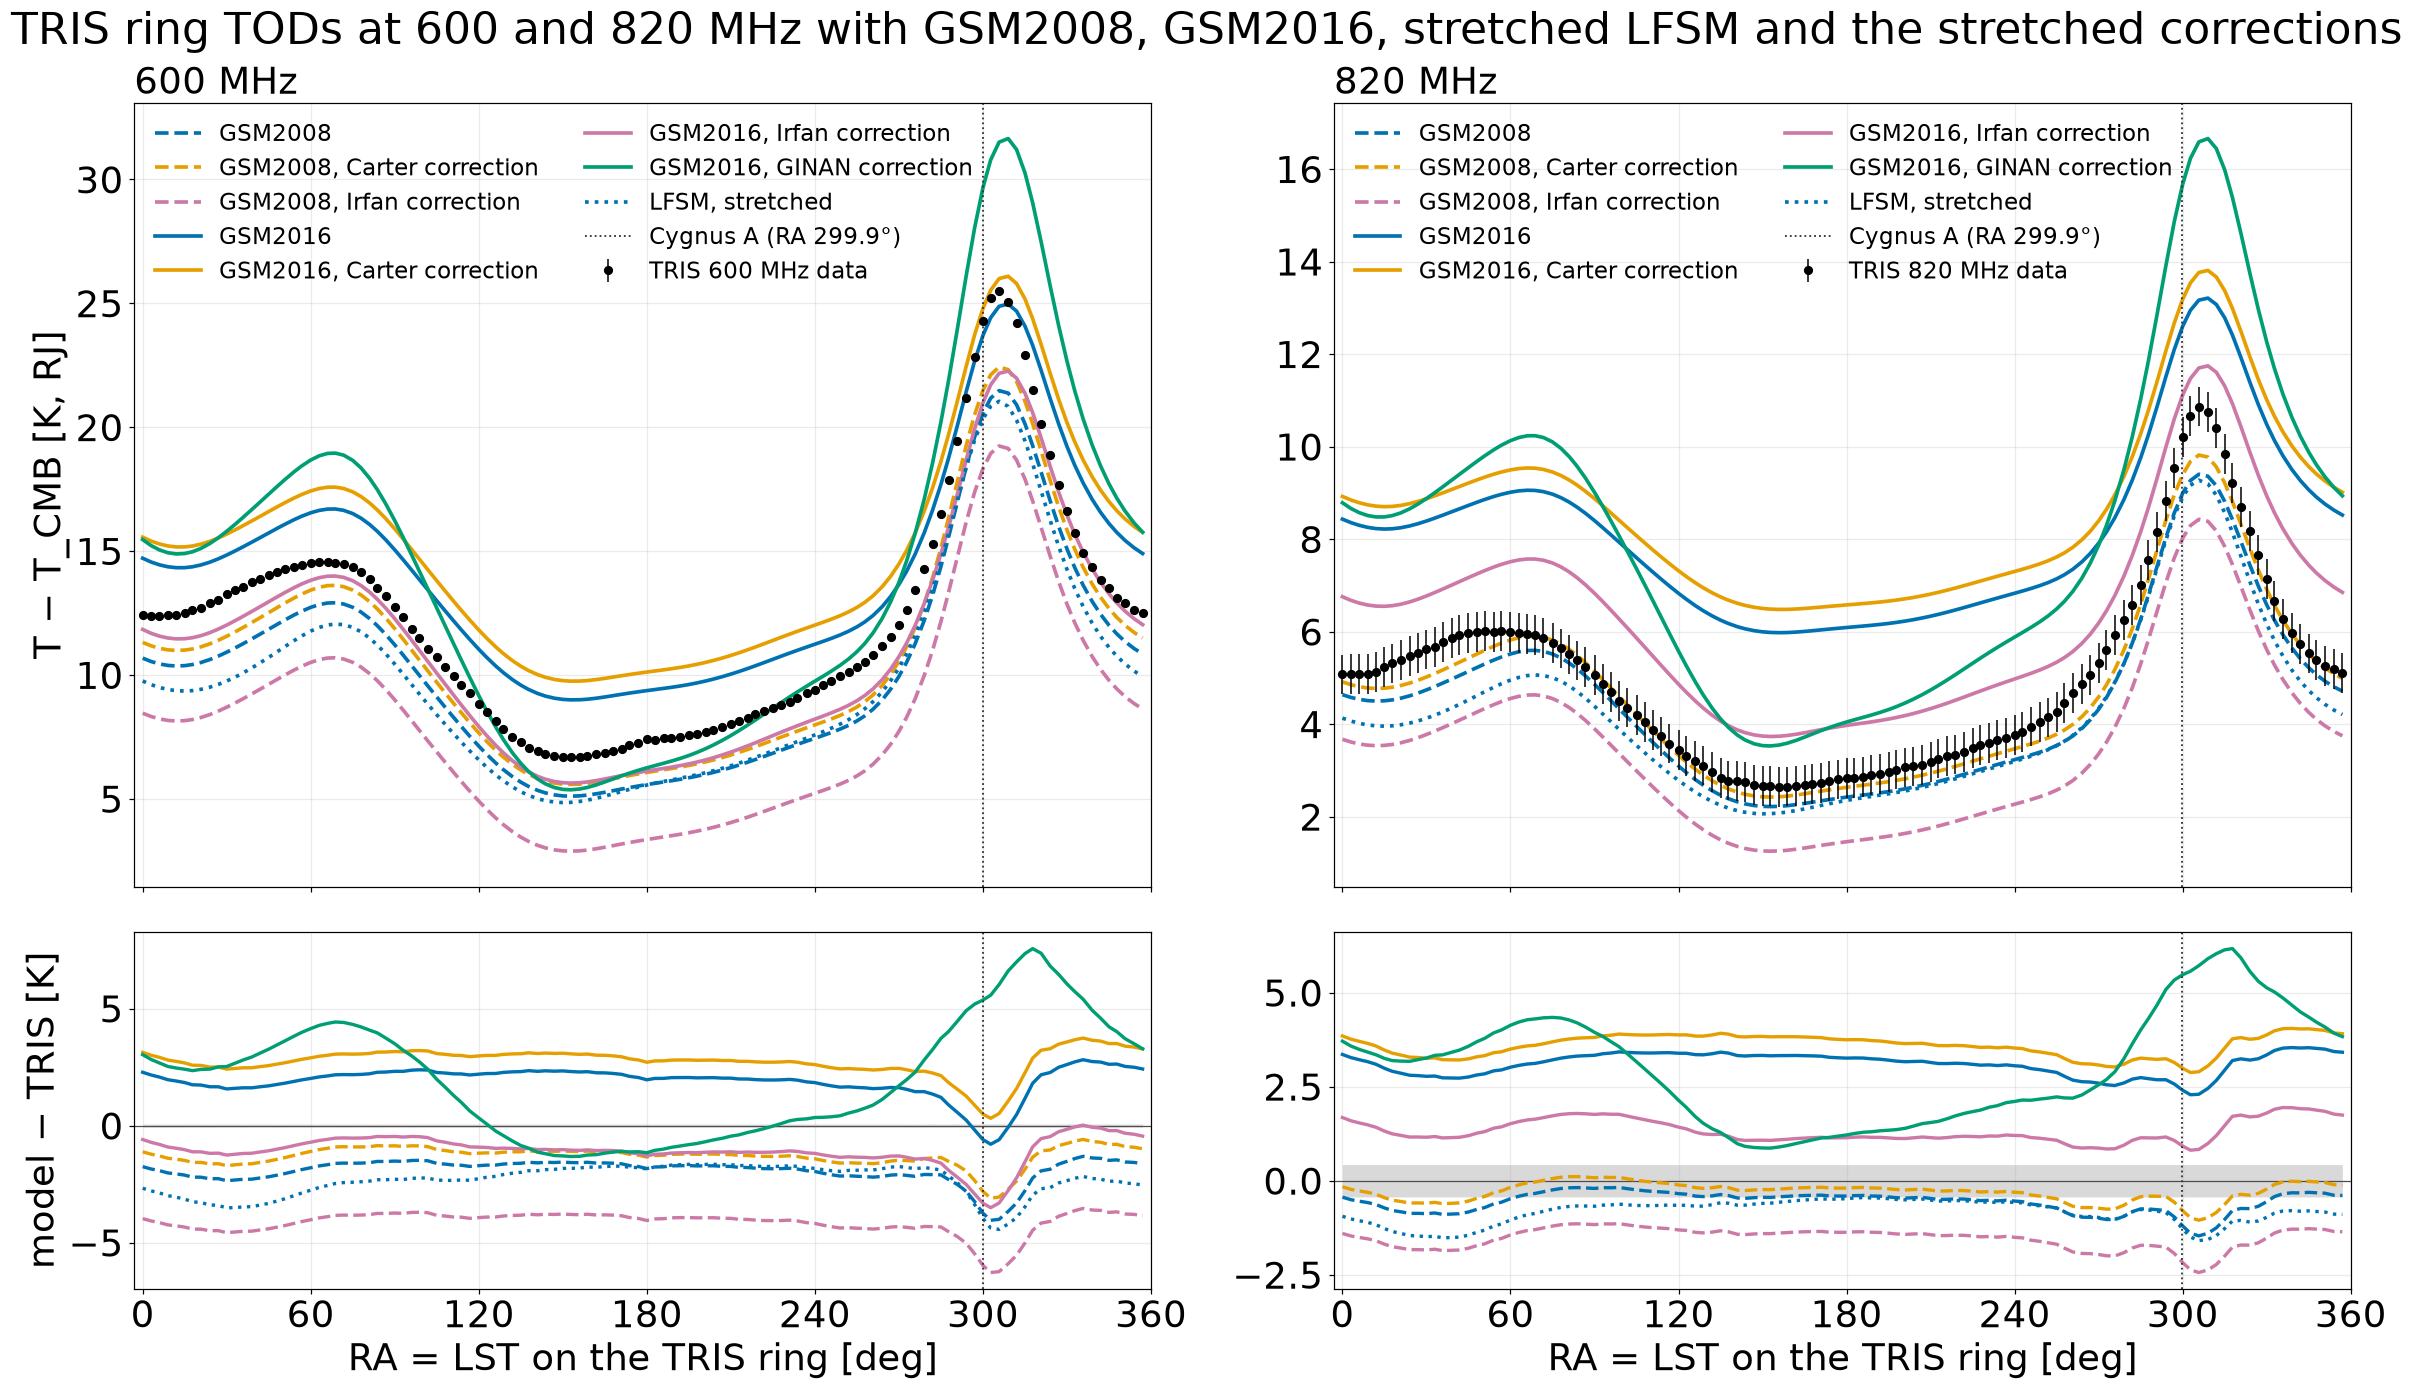

saved model_comparison/phil_plots/plot6_tods_600_820_data_vs_models.png


In [14]:
# Colour = correction, line style = base model (Okabe-Ito, colourblind-safe)
CORR_COL = {"none": "#0072B2", "Carter correction": "#E69F00", "Irfan correction": "#CC79A7", "GINAN correction": "#009E73",
            "stretched": "#0072B2"}
BASE_LS = {"GSM2008": "--", "GSM2016": "-", "LFSM": ":"}
PLOT6_MODELS = [n for n in ("GSM2008", "GSM2008, Carter correction", "GSM2008, Irfan correction", "GSM2016",
                            "GSM2016, Carter correction", "GSM2016, Irfan correction", "GSM2016, GINAN correction",
                            "LFSM, stretched")
                if (n, "TRIS_600") in T_GSM]
def style6(n):
    base, _, corr = n.partition(", ")
    return dict(color=CORR_COL[corr or "none"], ls=BASE_LS[base])
fig, axes = plt.subplots(2, 2, figsize=(26, 14), sharex=True,
                         gridspec_kw=dict(height_ratios=[2.2, 1], hspace=0.08, wspace=0.18))
for c, k in enumerate(NU_TRIS):
    ax, ar = axes[0, c], axes[1, c]
    ax.errorbar(RA, T[k], yerr=S[k], fmt="o", ms=5, color="black", elinewidth=1, capsize=0,
                label=f"TRIS {k.split('_')[1]} MHz data", zorder=3)
    ar.fill_between(RA, -S[k], S[k], color="0.85", lw=0, label="TRIS ±1σ")
    ar.axhline(0, color="0.3", lw=0.8)
    for n in PLOT6_MODELS:
        ax.plot(RA, T_GSM[(n, k)], lw=2.4, **style6(n), label=n)
        ar.plot(RA, T_GSM[(n, k)] - T[k], lw=2.2, **style6(n))
    for a in (ax, ar):
        a.axvline(299.9, color="0.2", ls=":", lw=1.2, label="Cygnus A (RA 299.9°)" if a is ax else None)
        a.grid(alpha=0.25)
    ax.set_title(f"{k.split('_')[1]} MHz", loc="left")
    ax.legend(frameon=False, loc="upper left", fontsize=15, ncol=2)
    ar.set_xlabel("RA = LST on the TRIS ring [deg]")
    ar.set_xlim(-3, 360); ar.set_xticks(np.arange(0, 361, 60))
axes[0, 0].set_ylabel("T − T_CMB [K, RJ]")
axes[1, 0].set_ylabel("model − TRIS [K]")
fig.suptitle("TRIS ring TODs at 600 and 820 MHz with GSM2008, GSM2016, stretched LFSM and the stretched corrections", y=0.94)
save(fig, "plot6_tods_600_820_data_vs_models")

### Plot 6a — every Plot 6 model fitted to the TRIS TODs (a new, TRIS-calibrated model)

Each model in Plot 6 is fitted to the TRIS ring data at each frequency with a scale and an offset,

$$T_\mathrm{TRIS}(\nu) = a_\nu\,T_\mathrm{model}(\nu) + b_\nu ,$$

by weighted least squares with the TRIS ring errors (statistical ⊕ zero level, `ring_sigma`). The fitted
$a_\nu T_\mathrm{model} + b_\nu$ is that model **calibrated to TRIS**: the new model at 600 and 820 MHz. The plot shows TRIS
minus each calibrated model along the ring (K), so it shows only what a scale and offset cannot fix; the grey band is the
TRIS ±1σ. The table gives a, b, their 1σ, χ²/ν and the rms residual. σ are scaled by √(χ²/ν) when it is above 1.

> **⚠ Caveats.** The 120 ring samples are correlated (3° apart under a ~20° beam), so every σ is an underestimate
> (roughly ×2.6). The TRIS zero-level error is common to the whole ring but is treated as independent per sample; at
> 600 MHz it dominates σ (≈ 0.07 K), so χ²/ν there is large and the fit is driven by the ring's shape.

saved model_comparison/phil_plots/plot6a_models_fitted_to_tris.csv

                     model TRIS band     a   σ_a  b [K]  σ_b [K]   χ²/ν  rms of TRIS − calibrated model [K]  rms before calibration [K]   N
                   GSM2008 600.5 MHz 1.073 0.008  1.177    0.092 32.899                               0.383                       1.990 120
                   GSM2008 817.8 MHz 1.084 0.021  0.194    0.102  0.291                               0.230                       0.631 120
GSM2008, Carter correction 600.5 MHz 1.043 0.008  0.837    0.094 32.888                               0.383                       1.373 120
GSM2008, Carter correction 817.8 MHz 1.053 0.021  0.046    0.105  0.291                               0.230                       0.388 120
 GSM2008, Irfan correction 600.5 MHz 1.074 0.008  3.553    0.075 32.977                               0.384                       4.178 120
 GSM2008, Irfan correction 817.8 MHz 1.085 0.021  1.236    0.084  0.293                     

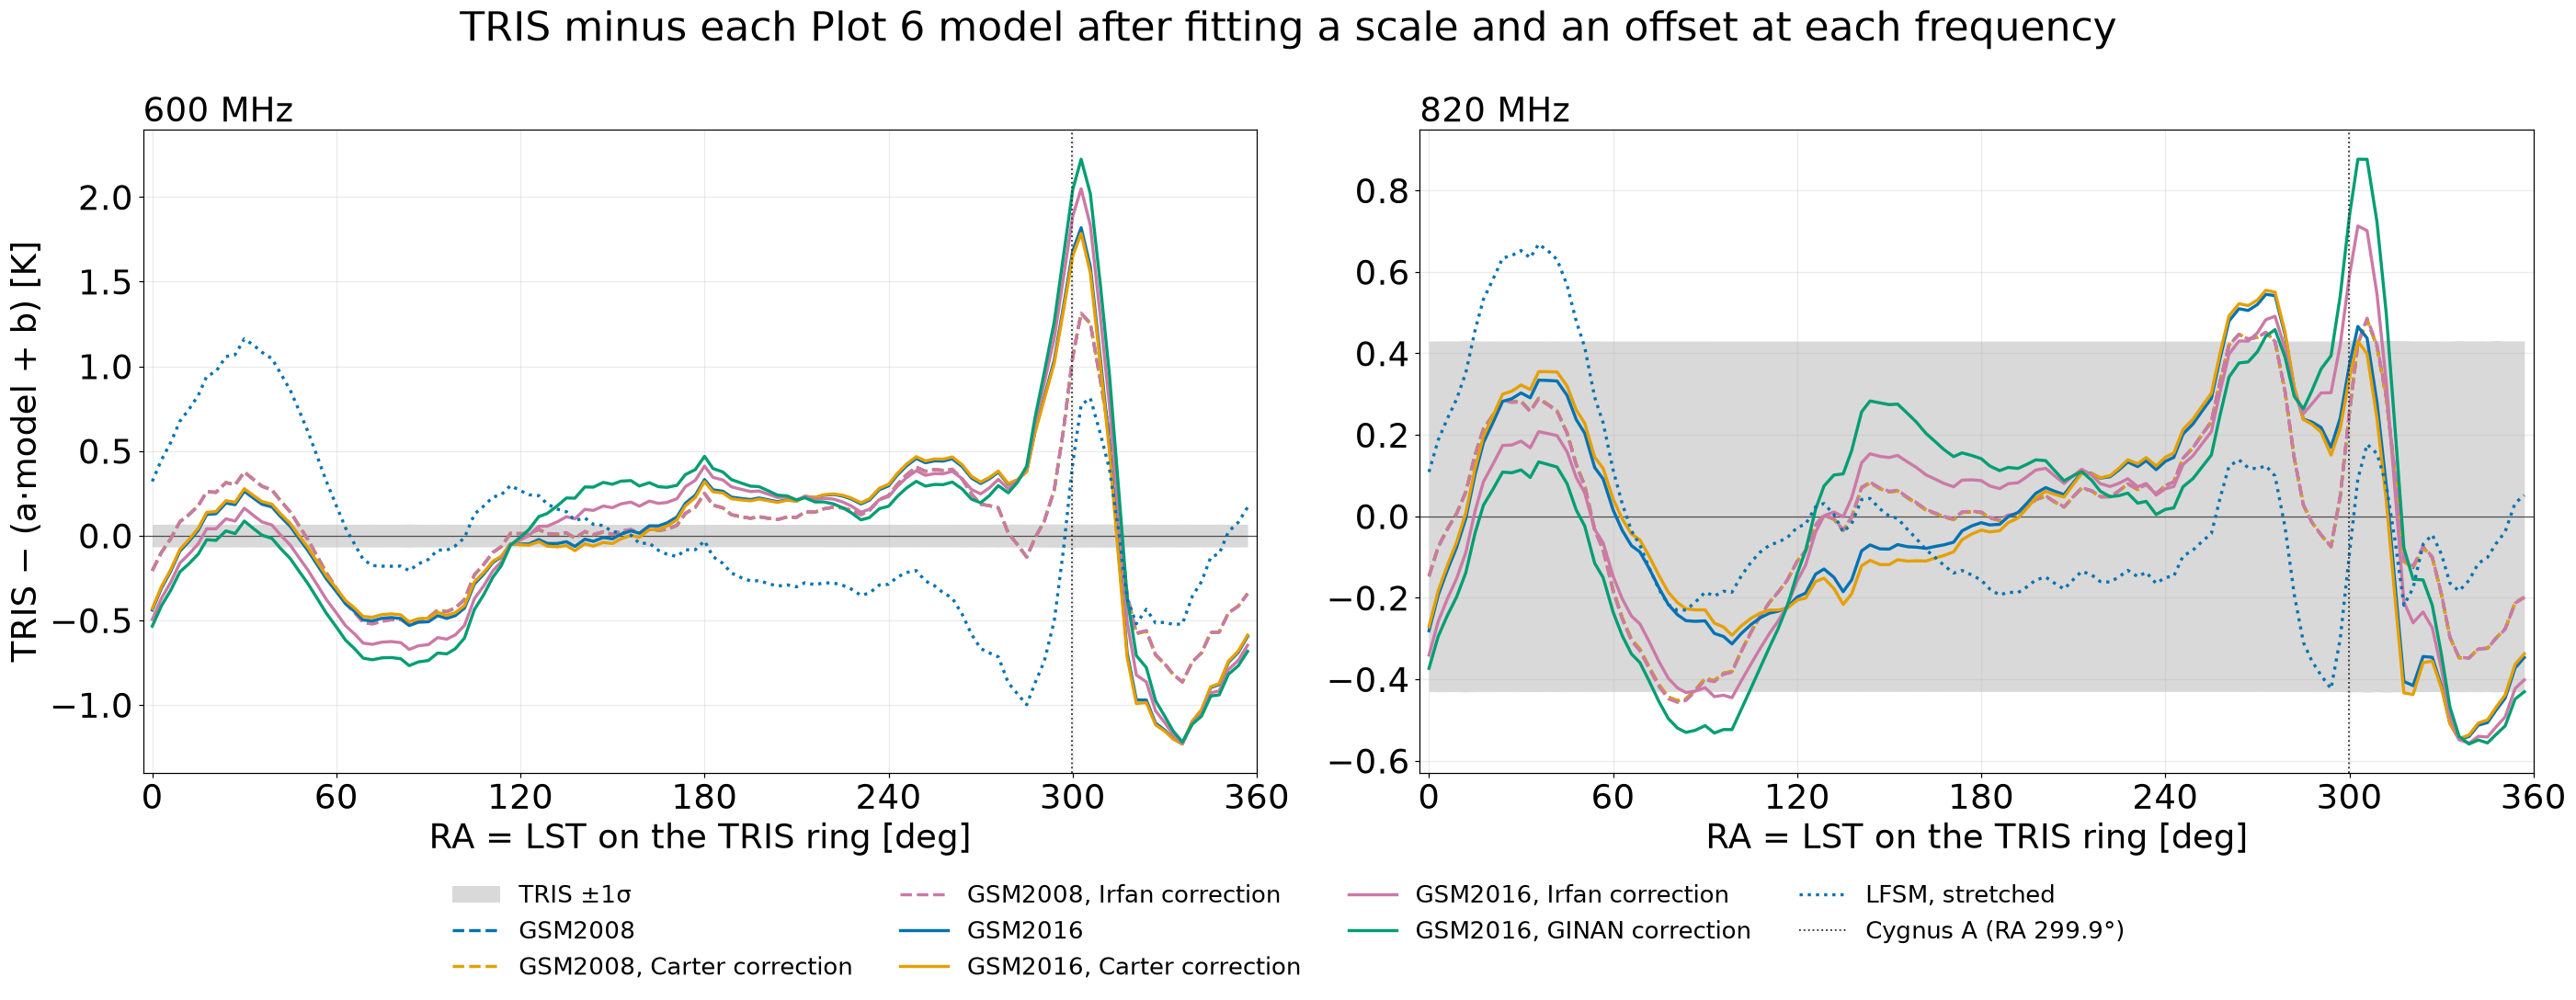

saved model_comparison/phil_plots/plot6a_tris_minus_calibrated_models.png


In [15]:
def wls_line(x, y, s):
    # y = a x + b by weighted least squares; returns a, b, their covariance (scaled by chi2/nu if > 1), chi2/nu.
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(s) & (s > 0)
    A = np.vstack([x[ok], np.ones(ok.sum())]).T / s[ok, None]
    p, *_ = np.linalg.lstsq(A, y[ok] / s[ok], rcond=None)
    chi2nu = float(np.sum(((y[ok] - A @ p * s[ok]) / s[ok]) ** 2) / (ok.sum() - 2))
    cov = np.linalg.inv(A.T @ A) * max(1.0, chi2nu)
    return p[0], p[1], cov, chi2nu, int(ok.sum())

FIT6 = {}
rows = []
for n in PLOT6_MODELS:
    for k in NU_TRIS:
        a, b, cov, c2, nn = wls_line(T_GSM[(n, k)], T[k], S[k])
        res = T[k] - (a * T_GSM[(n, k)] + b)
        FIT6[(n, k)] = dict(a=a, b=b, cov=cov, chi2nu=c2, res=res)
        rows.append({"model": n, "TRIS band": f"{NU_TRIS[k]:g} MHz", "a": a, "σ_a": np.sqrt(cov[0, 0]), "b [K]": b,
                     "σ_b [K]": np.sqrt(cov[1, 1]), "χ²/ν": c2, "rms of TRIS − calibrated model [K]": np.sqrt(np.nanmean(res ** 2)),
                     "rms before calibration [K]": np.sqrt(np.nanmean((T_GSM[(n, k)] - T[k]) ** 2)), "N": nn})
fit6_df = pd.DataFrame(rows)
fit6_df.to_csv(OUT_DIR / "plot6a_models_fitted_to_tris.csv", index=False)
print(f"saved {(OUT_DIR / 'plot6a_models_fitted_to_tris.csv').relative_to(REPO)}\n")
with pd.option_context("display.width", 250):
    print(fit6_df.round(3).to_string(index=False))
for k in NU_TRIS:
    sub = fit6_df[fit6_df["TRIS band"] == f"{NU_TRIS[k]:g} MHz"].sort_values("rms of TRIS − calibrated model [K]")
    print(f"\nbest after calibration at {NU_TRIS[k]:g} MHz: {sub.iloc[0]['model']} "
          f"(rms {sub.iloc[0]['rms of TRIS − calibrated model [K]']:.3f} K)")

fig, axes = plt.subplots(1, 2, figsize=(26, 9), sharex=True)
for ax, k in zip(axes, NU_TRIS):
    ax.fill_between(RA, -S[k], S[k], color="0.85", lw=0, label="TRIS ±1σ")
    ax.axhline(0, color="0.3", lw=0.8)
    for n in PLOT6_MODELS:
        ax.plot(RA, FIT6[(n, k)]["res"], lw=2.2, **style6(n), label=n)
    ax.axvline(299.9, color="0.2", ls=":", lw=1.2, label="Cygnus A (RA 299.9°)")
    ax.set_title(f"{k.split('_')[1]} MHz", loc="left")
    ax.set_xlabel("RA = LST on the TRIS ring [deg]"); ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60))
    ax.grid(alpha=0.25)
axes[0].set_ylabel("TRIS − (a·model + b) [K]")
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, fontsize=17, ncol=4, loc="lower center",
           bbox_to_anchor=(0.5, -0.12))
fig.suptitle("TRIS minus each Plot 6 model after fitting a scale and an offset at each frequency", y=0.97)
fig.tight_layout()
save(fig, "plot6a_tris_minus_calibrated_models")

### Plot 6b — a suggested correction to GSM2008 and GSM2016

From Plot 6a, the fitted scale of GSM2008 and of GSM2016 is almost the same at 600 and 820 MHz, so the correction has
**one gain for both frequencies** and **one constant offset** (in K, the same form as the Carter and Irfan offsets). Two
forms of the gain are fitted, each jointly to both TRIS rings (240 points):

$$\text{constant gain:}\quad T_\mathrm{corrected}(\nu) = g\,T_\mathrm{GSM}(\nu) + z,$$

$$\text{gain} \times (\nu/408)^\delta:\quad T_\mathrm{corrected}(\nu) = g\,(\nu/408\,\mathrm{MHz})^{\delta}\,T_\mathrm{GSM}(\nu) + z .$$

The second adds a **weak power law in frequency** to the gain. Since the factor is 1 at 408 MHz, $g$ is still the gain at
408 MHz, and $\delta$ tilts the model's spectral index: the corrected model's β is the GSM's β + δ. It is fitted by
non-linear least squares (`scipy.optimize.least_squares`), the constant-gain form by linear least squares; σ are from
the Jacobian, scaled by √(χ²/ν) when it is above 1. With only two frequencies, δ is set by the ratio of the 820 to the
600 MHz scale, and how the offset changes with frequency cannot be measured, so a constant offset is an assumption.

The left panel shows the per-frequency scales $a_\nu$ from Plot 6a with the joint gain of each form ($g$, or
$g(\nu/408)^\delta$ with its ±1σ band); the right panel the per-frequency offsets $b_\nu$ with the joint $z$, extended
down to 408 MHz. Colour marks the base model, line style the form (solid: constant gain, dashed: gain × (ν/408)^δ).
**σ are underestimates** (correlated samples; common TRIS zero level treated as independent).

**Result (2026-10-28).** With δ free, the fit does **not** find a weak factor: δ = −0.58 ± 0.12 (GSM2008) and
−0.26 ± 0.09 (GSM2016), with χ² lower by 441 and 290 for the one extra parameter. That δ is not a spectral tilt of the
model: Plot 6a's scales, each fitted with its own offset, give δ = ln(a₈₂₀/a₆₀₀)/ln(817.8/600.5) = +0.03 ± 0.07
(GSM2008) and −0.04 ± 0.07 (GSM2016), consistent with zero. The large δ appears because the offset is forced to be
the same at both frequencies, while the rings want different offsets (b = +1.18 / +0.19 K for GSM2008, −3.08 /
−3.68 K for GSM2016). With z fixed by the precise 600 MHz ring, δ is the only way left to lower the model at 820 MHz.
It does fix 820 MHz (rms 0.91 → 0.43 K for GSM2008, 0.71 → 0.30 K for GSM2016; 600 MHz unchanged), but extrapolated
down to 408 MHz it raises the gain to 1.34 and 1.20 (Plot 6c). So the data say the gain itself has no measurable
frequency dependence between 600 and 820 MHz; what changes with frequency is the offset, which two frequencies with a
shared z cannot separate from δ.

saved model_comparison/phil_plots/plot6b_gsm_corrections.csv

  model        gain form  g (gain at 408 MHz)    σ_g  δ (frequency power law of the gain)    σ_δ   z [K]  σ_z [K]  corr(g, z)        χ²    χ²/ν   N  rms TRIS − corrected at 600.5 MHz [K]  rms TRIS − corrected at 817.8 MHz [K]
GSM2008    constant gain               1.0803 0.0061                                  NaN    NaN  1.0856   0.0668     -0.9207 4447.7398 18.6880 240                                 0.3848                                 0.9053
GSM2008 gain × (ν/408)^δ               1.3442 0.0636                              -0.5773 0.1243  1.1532   0.0649      0.1247 4006.7065 16.9059 240                                 0.3834                                 0.4348
GSM2016    constant gain               1.0894 0.0083                                  NaN    NaN -3.1663   0.1207     -0.9569 8019.4754 33.6953 240                                 0.5403                                 0.7113
GSM2016 gain × (ν/408)^δ          

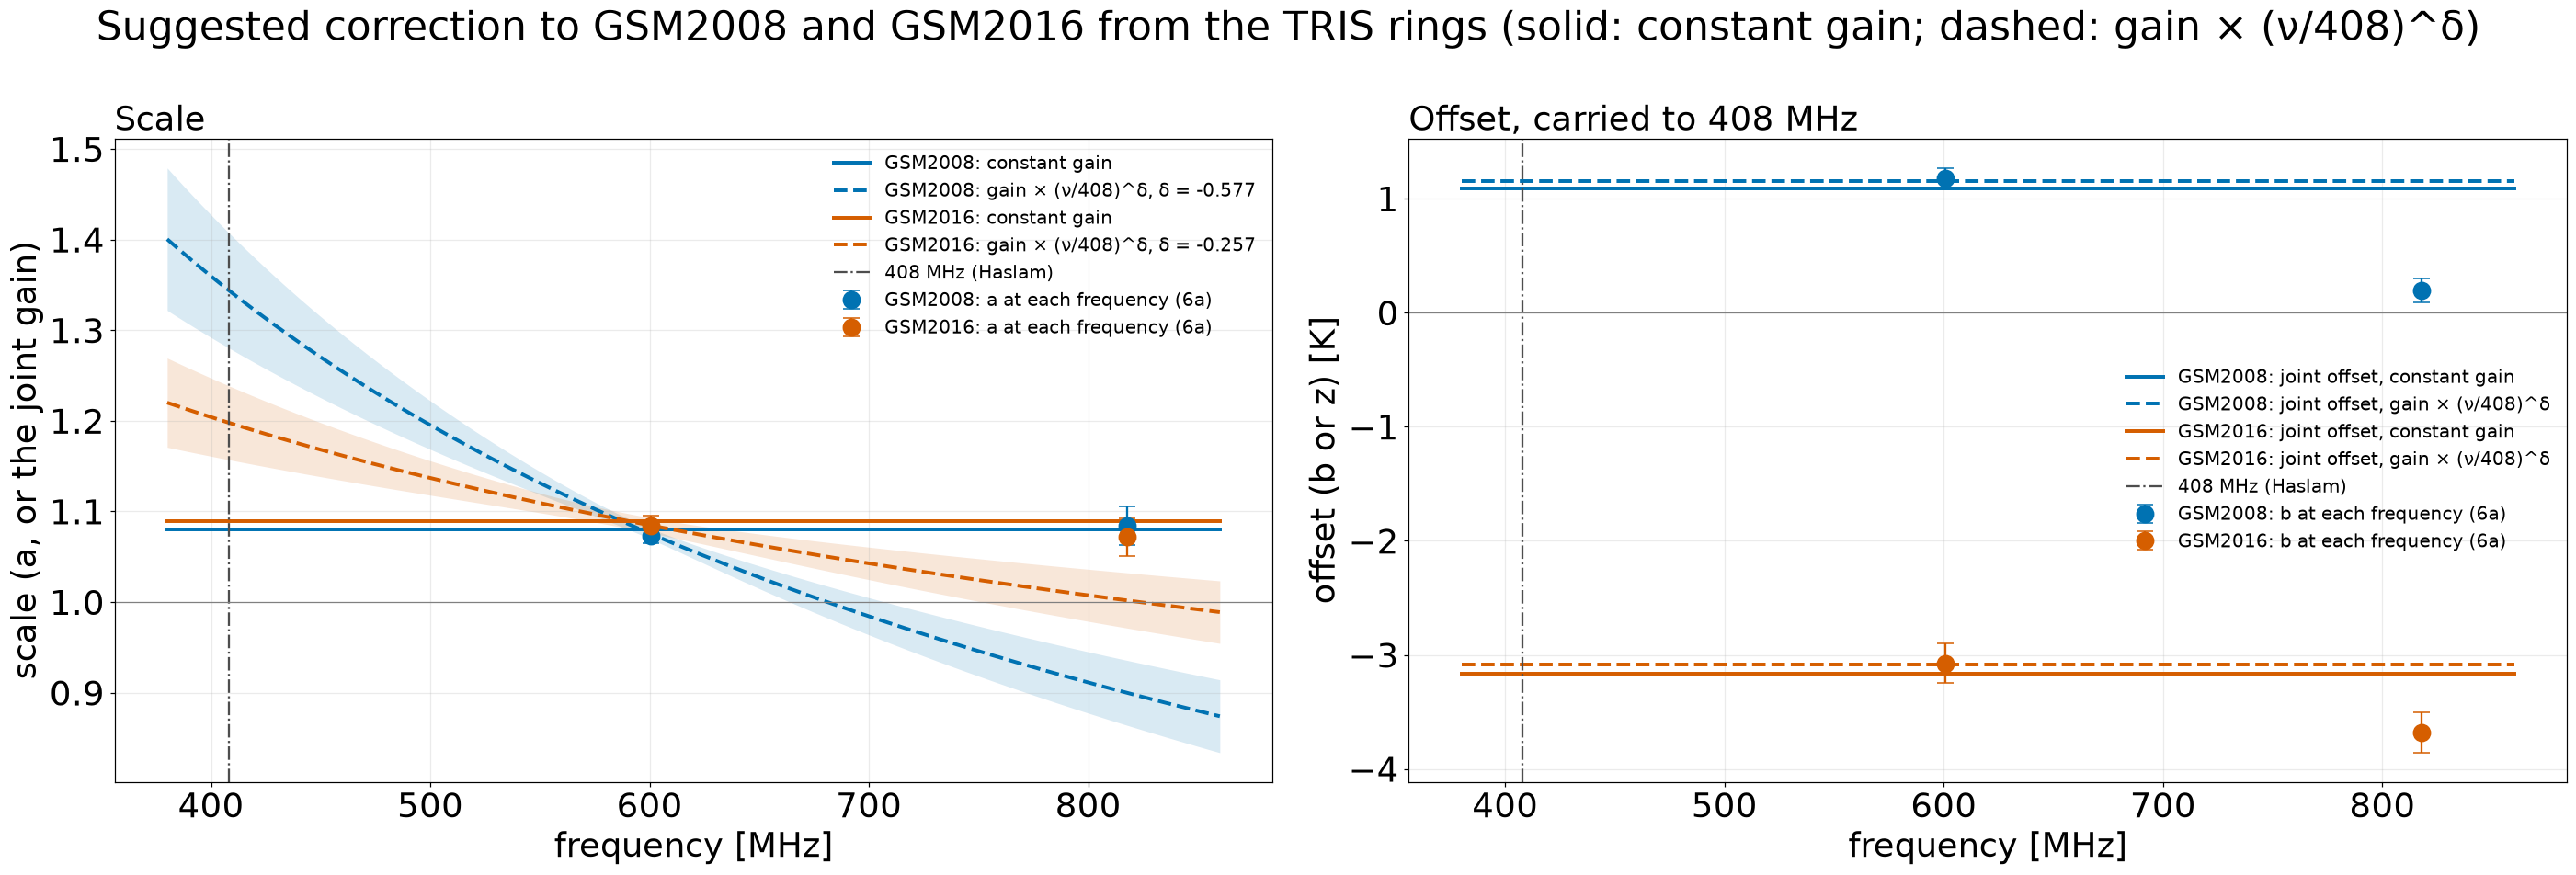

saved model_comparison/phil_plots/plot6b_gsm_correction.png


In [16]:
# Two forms of the correction, both with one constant offset z (Plot 6b):
#   "constant gain":     T = g T_GSM(nu) + z
#   "gain × (ν/408)^δ":  T = g (nu/408)^delta T_GSM(nu) + z   (a weak power law in frequency; delta tilts beta)
from scipy.optimize import least_squares

FORMS = ["constant gain", "gain × (ν/408)^δ"]
MAIN_FORM = "constant gain"
FORM_LS = {"constant gain": "-", "gain × (ν/408)^δ": "--"}
GSM_BASE = ["GSM2008", "GSM2016"]
GSM_COL = {"GSM2008": "#0072B2", "GSM2016": "#D55E00"}

def corr_model(p, M, f):
    # p = (g, z) or (g, z, delta); M = T_GSM(nu); f = nu / 408 MHz
    d = p[2] if len(p) > 2 else 0.0
    return p[0] * f ** d * M + p[1]

def corr_jac(p, M, f):
    # d corr_model / d p, one row per sample
    d = p[2] if len(p) > 2 else 0.0
    cols = [f ** d * M, np.ones_like(M)]
    if len(p) > 2:
        cols.append(p[0] * f ** d * M * np.log(f))
    return np.vstack(cols).T

def joint_fit(n, form):
    # Fit both TRIS rings at once, weighted by the TRIS ring errors.
    M = np.concatenate([T_GSM[(n, k)] for k in NU_TRIS])
    F = np.concatenate([np.full(N, nu / 408.0) for nu in NU_TRIS.values()])
    Y = np.concatenate([T[k] for k in NU_TRIS]); W = np.concatenate([S[k] for k in NU_TRIS])
    ok = np.isfinite(M) & np.isfinite(Y) & np.isfinite(W) & (W > 0)
    M, F, Y, W = M[ok], F[ok], Y[ok], W[ok]
    p, *_ = np.linalg.lstsq(np.vstack([M, np.ones_like(M)]).T / W[:, None], Y / W, rcond=None)
    if form != MAIN_FORM:
        p = least_squares(lambda q: (Y - corr_model(q, M, F)) / W, np.r_[p, 0.0], x_scale="jac").x
    chi2 = float(np.sum(((Y - corr_model(p, M, F)) / W) ** 2))
    chi2nu = chi2 / (Y.size - p.size)
    J = corr_jac(p, M, F) / W[:, None]
    cov = np.linalg.inv(J.T @ J) * max(1.0, chi2nu)
    rms = {k: float(np.sqrt(np.nanmean((T[k] - corr_model(p, T_GSM[(n, k)], nu / 408.0)) ** 2)))
           for k, nu in NU_TRIS.items()}
    return dict(p=p, g=p[0], z=p[1], delta=float(p[2]) if p.size > 2 else 0.0, cov=cov, chi2=chi2, chi2nu=chi2nu,
                rms=rms, n=int(Y.size))

def corrected(n, form, M, nu):
    # The corrected model at frequency nu for model TOD M, and its 1 sigma from the fit's covariance.
    r = CORR[(n, form)]
    f = np.full_like(M, nu / 408.0)
    J = corr_jac(r["p"], M, f)
    return corr_model(r["p"], M, f), np.sqrt(np.einsum("ij,jk,ik->i", J, r["cov"], J))

def form_label(n, form):
    r = CORR[(n, form)]
    if form == MAIN_FORM:
        return f"{r['g']:.3f} × {n} {r['z']:+.2f} K"
    return f"{r['g']:.3f} (ν/408)^{r['delta']:+.3f} × {n} {r['z']:+.2f} K"

CORR = {(n, form): joint_fit(n, form) for n in GSM_BASE for form in FORMS}
rows = []
for (n, form), r in CORR.items():
    sd = np.sqrt(np.diag(r["cov"]))
    rows.append({"model": n, "gain form": form, "g (gain at 408 MHz)": r["g"], "σ_g": sd[0],
                 "δ (frequency power law of the gain)": r["delta"] if form != MAIN_FORM else np.nan,
                 "σ_δ": sd[2] if form != MAIN_FORM else np.nan,
                 "z [K]": r["z"], "σ_z [K]": sd[1], "corr(g, z)": r["cov"][0, 1] / (sd[0] * sd[1]),
                 "χ²": r["chi2"], "χ²/ν": r["chi2nu"], "N": r["n"],
                 **{f"rms TRIS − corrected at {NU_TRIS[k]:g} MHz [K]": v for k, v in r["rms"].items()}})
corr_df = pd.DataFrame(rows)
corr_df.to_csv(OUT_DIR / "plot6b_gsm_corrections.csv", index=False)
print(f"saved {(OUT_DIR / 'plot6b_gsm_corrections.csv').relative_to(REPO)}\n")
with pd.option_context("display.width", 300):
    print(corr_df.round(4).to_string(index=False))
for n in GSM_BASE:
    c0, c1 = CORR[(n, FORMS[0])], CORR[(n, FORMS[1])]
    print(f"\n{n}: δ = {c1['delta']:+.4f} ± {np.sqrt(c1['cov'][2, 2]):.4f}; χ² falls by {c0['chi2'] - c1['chi2']:.1f} "
          f"for one extra parameter")
    for form in FORMS:
        print(f"  suggested correction ({form}): {n}_corrected = {form_label(n, form)}")
    # For comparison: the δ implied by Plot 6a's per-frequency scales, each fitted with its own offset b_nu.
    (k6, k8) = NU_TRIS
    a6, a8 = FIT6[(n, k6)]["a"], FIT6[(n, k8)]["a"]
    s6, s8 = np.sqrt(FIT6[(n, k6)]["cov"][0, 0]), np.sqrt(FIT6[(n, k8)]["cov"][0, 0])
    lr = np.log(NU_TRIS[k8] / NU_TRIS[k6])
    print(f"  δ from 6a's scales (own offset at each frequency): ln(a_820 / a_600) / ln(817.8 / 600.5) = "
          f"{np.log(a8 / a6) / lr:+.3f} ± {np.hypot(s6 / a6, s8 / a8) / lr:.3f}")

nus = np.linspace(380, 860, 200)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(26, 9))
for n in GSM_BASE:
    col = GSM_COL[n]
    fa = [FIT6[(n, k)] for k in NU_TRIS]
    a1.errorbar(list(NU_TRIS.values()), [f["a"] for f in fa], yerr=[np.sqrt(f["cov"][0, 0]) for f in fa], fmt="o", ms=12,
                color=col, capsize=6, label=f"{n}: a at each frequency (6a)")
    a2.errorbar(list(NU_TRIS.values()), [f["b"] for f in fa], yerr=[np.sqrt(f["cov"][1, 1]) for f in fa], fmt="o", ms=12,
                color=col, capsize=6, label=f"{n}: b at each frequency (6a)")
    for form in FORMS:
        r = CORR[(n, form)]
        style = dict(color=col, ls=FORM_LS[form], lw=2.6)
        gain = r["g"] * (nus / 408.0) ** r["delta"]
        if form != MAIN_FORM:      # ±1σ of g (ν/408)^δ from cov(g, δ)
            Jg = np.vstack([(nus / 408.0) ** r["delta"], gain * np.log(nus / 408.0)]).T
            cg = r["cov"][np.ix_([0, 2], [0, 2])]
            sg = np.sqrt(np.einsum("ij,jk,ik->i", Jg, cg, Jg))
            a1.fill_between(nus, gain - sg, gain + sg, color=col, alpha=0.15, lw=0)
        a1.plot(nus, gain, **style, label=f"{n}: {form}" + (f", δ = {r['delta']:+.3f}" if form != MAIN_FORM else ""))
        a2.plot(nus, np.full_like(nus, r["z"]), **style, label=f"{n}: joint offset, {form}")
for a in (a1, a2):
    a.axvline(408, color="0.3", ls="-.", lw=1.5, label="408 MHz (Haslam)")
    a.set_xlabel("frequency [MHz]"); a.grid(alpha=0.25)
a1.axhline(1, color="0.5", lw=0.8); a2.axhline(0, color="0.5", lw=0.8)
a1.set_ylabel("scale (a, or the joint gain)"); a2.set_ylabel("offset (b or z) [K]")
a1.set_title("Scale", loc="left"); a2.set_title("Offset, carried to 408 MHz", loc="left")
a1.legend(frameon=False, fontsize=13); a2.legend(frameon=False, fontsize=13)
fig.suptitle("Suggested correction to GSM2008 and GSM2016 from the TRIS rings (solid: constant gain; "
             "dashed: gain × (ν/408)^δ)", y=0.98)
fig.tight_layout()
save(fig, "plot6b_gsm_correction")

### Plot 6c — the corrected GSM models' 408 MHz TOD against Haslam and its corrections

The corrections of Plot 6b applied to GSM2008's and GSM2016's 408 MHz ring TODs (beam-matched, notebook 18). At
408 MHz the frequency factor is 1, so both forms give $g\,T_\mathrm{GSM}(408) + z$, each with its own fitted $g$ and $z$.
This is the 408 MHz sky that TRIS, through each GSM's spectral shape, predicts. It is compared with Haslam
(uncorrected), Haslam + Carter and Haslam + Irfan (beam-matched). **Top:** the predicted TOD of each form (solid:
constant gain, dashed: gain × (ν/408)^δ) with its ±1σ band from the fit's covariance; **bottom:** each Haslam version
minus the prediction, in K, with the same line styles and the constant-gain prediction's ±1σ in grey. One column per
base model. The table gives the median and rms of each difference for both forms.

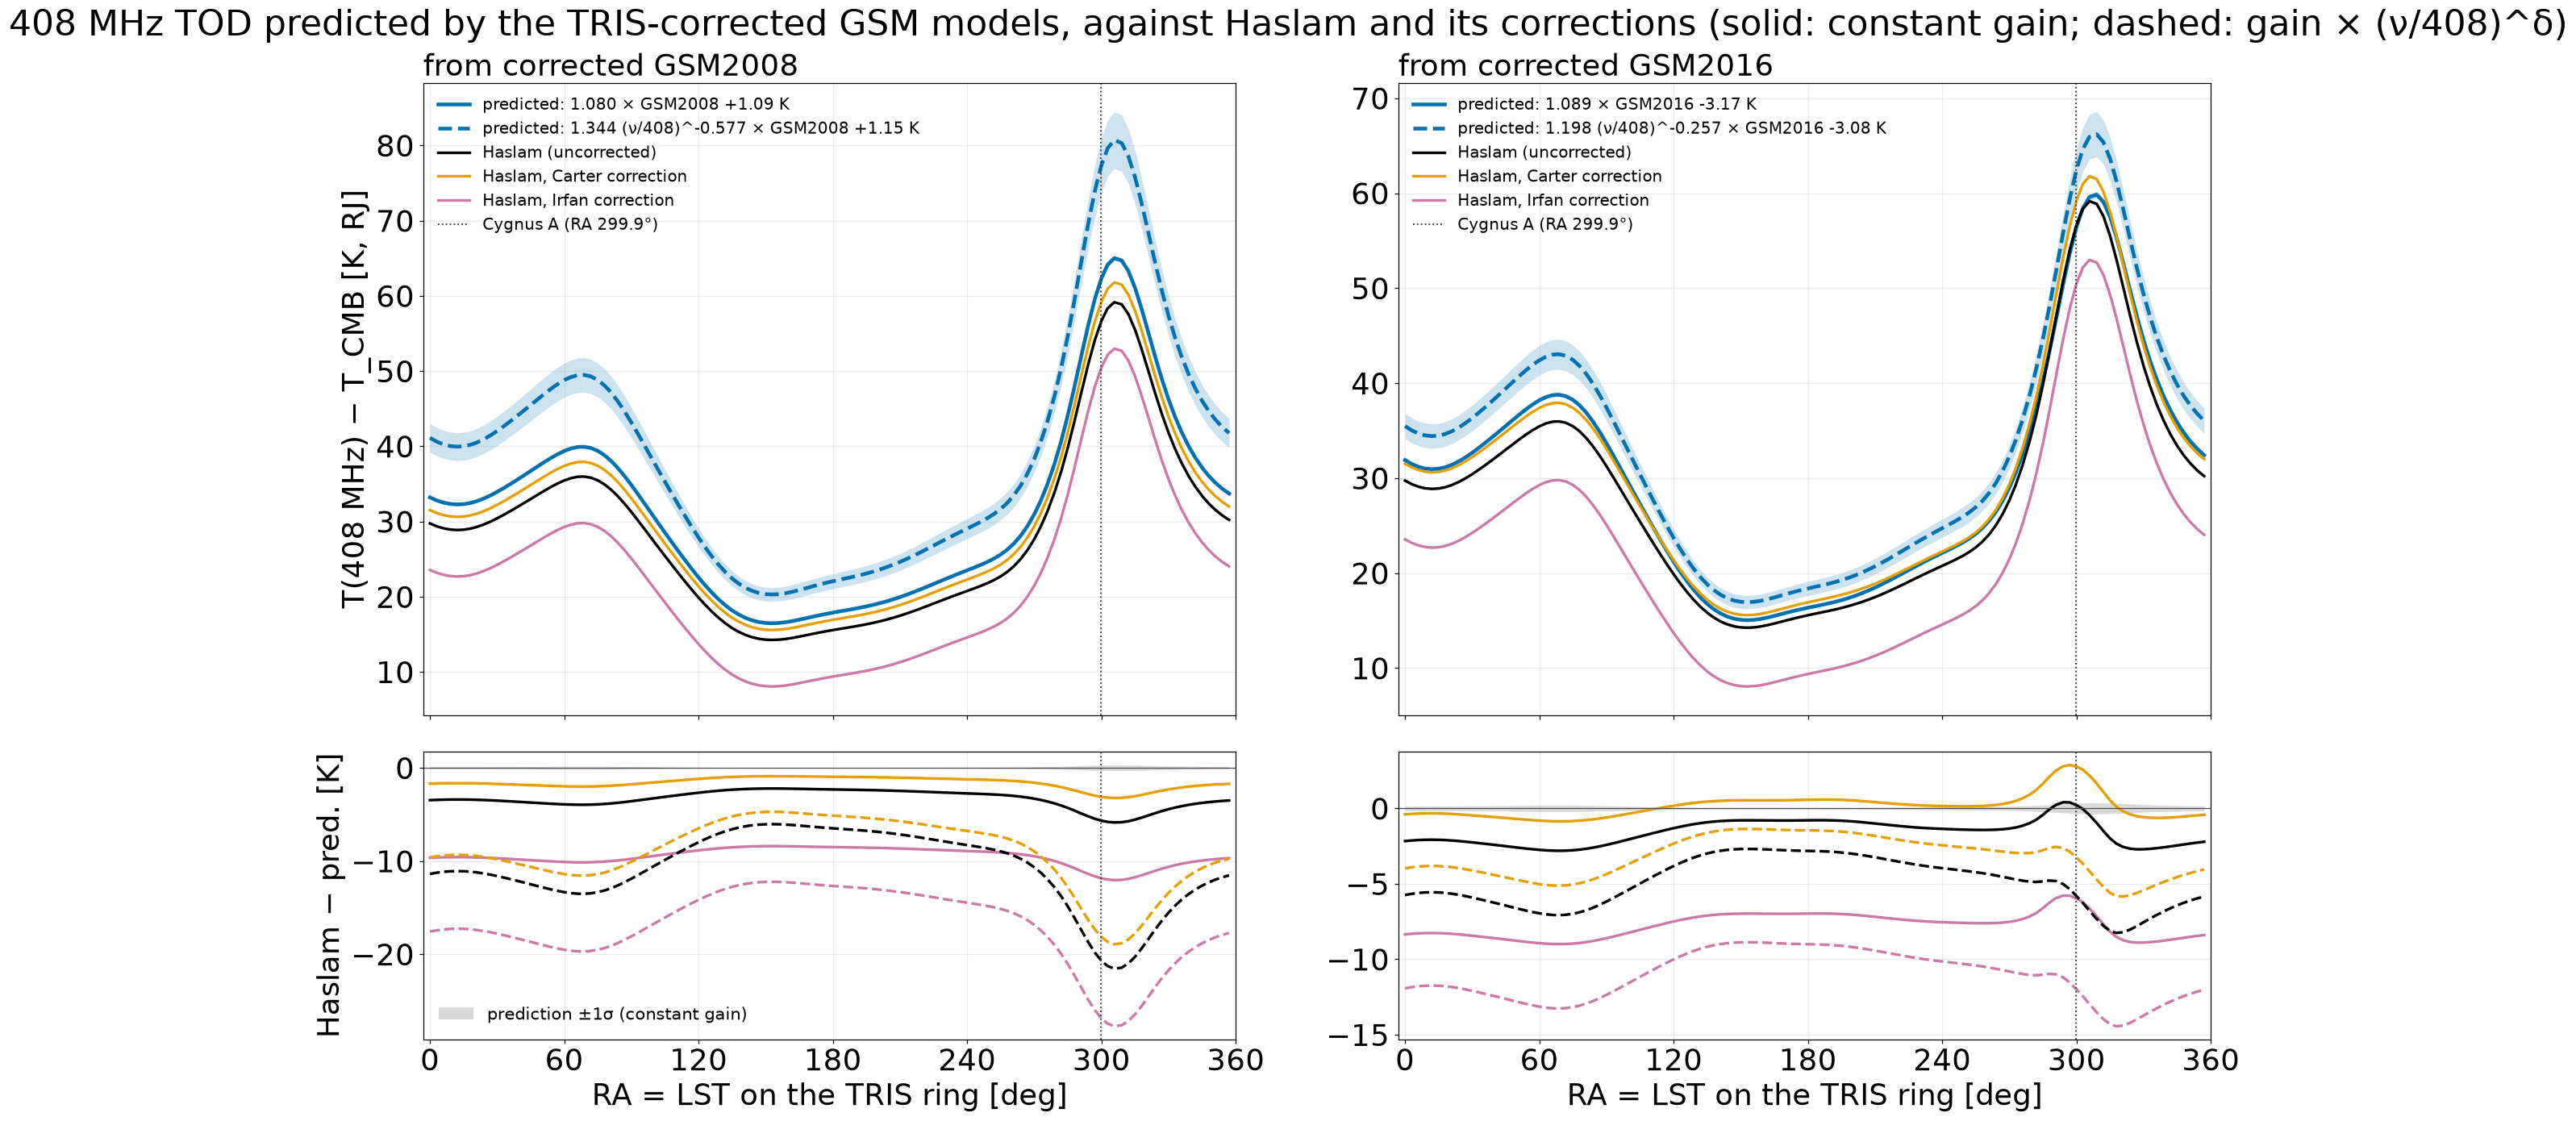

saved model_comparison/phil_plots/plot6c_predicted_408_vs_haslam.png
saved model_comparison/phil_plots/plot6c_haslam_vs_predicted_408.csv

prediction from        gain form            Haslam version  median (Haslam − prediction) [K]  rms [K]
        GSM2008    constant gain      Haslam (uncorrected)                             -3.40     3.49
        GSM2008    constant gain Haslam, Carter correction                             -1.65     1.73
        GSM2008    constant gain  Haslam, Irfan correction                             -9.58     9.59
        GSM2008 gain × (ν/408)^δ      Haslam (uncorrected)                            -11.09    11.63
        GSM2008 gain × (ν/408)^δ Haslam, Carter correction                             -9.35     9.89
        GSM2008 gain × (ν/408)^δ  Haslam, Irfan correction                            -17.28    17.56
        GSM2016    constant gain      Haslam (uncorrected)                             -1.42     1.78
        GSM2016    constant gain Haslam, Cart

In [17]:
HAS_STYLE = {"Haslam (uncorrected)": dict(color="black"),
             "Haslam, Carter correction": dict(color="#E69F00"),
             "Haslam, Irfan correction": dict(color="#CC79A7")}
def predict408(n, form):
    return corrected(n, form, T408[n], 408.0)

rows = []
fig, axes = plt.subplots(2, 2, figsize=(26, 14), sharex=True, gridspec_kw=dict(height_ratios=[2.2, 1], hspace=0.08))
for c, n in enumerate(GSM_BASE):
    ax, ar = axes[0, c], axes[1, c]
    for form in FORMS:
        pred, sig = predict408(n, form)
        ax.fill_between(RA, pred - sig, pred + sig, color="#0072B2", alpha=0.2, lw=0)
        ax.plot(RA, pred, color="#0072B2", lw=3, ls=FORM_LS[form], label=f"predicted: {form_label(n, form)}")
        if form == MAIN_FORM:
            ar.fill_between(RA, -sig, sig, color="0.85", lw=0, label="prediction ±1σ (constant gain)")
        for h, st in HAS_STYLE.items():
            d = T408[h] - pred
            ar.plot(RA, d, lw=2.2, ls=FORM_LS[form], **st)
            rows.append({"prediction from": n, "gain form": form, "Haslam version": h,
                         "median (Haslam − prediction) [K]": np.nanmedian(d), "rms [K]": np.sqrt(np.nanmean(d ** 2))})
    ar.axhline(0, color="0.3", lw=0.8)
    for h, st in HAS_STYLE.items():
        ax.plot(RA, T408[h], lw=2.2, **st, label=h)
    for a in (ax, ar):
        a.axvline(299.9, color="0.2", ls=":", lw=1.2, label="Cygnus A (RA 299.9°)" if a is ax else None)
        a.grid(alpha=0.25)
    ax.set_title(f"from corrected {n}", loc="left")
    ax.legend(frameon=False, fontsize=13, loc="upper left")
    ar.set_xlabel("RA = LST on the TRIS ring [deg]"); ar.set_xlim(-3, 360); ar.set_xticks(np.arange(0, 361, 60))
axes[0, 0].set_ylabel("T(408 MHz) − T_CMB [K, RJ]")
axes[1, 0].set_ylabel("Haslam − pred. [K]")
axes[1, 0].legend(frameon=False, fontsize=14, loc="lower left")
fig.suptitle("408 MHz TOD predicted by the TRIS-corrected GSM models, against Haslam and its corrections "
             "(solid: constant gain; dashed: gain × (ν/408)^δ)", y=0.94)
save(fig, "plot6c_predicted_408_vs_haslam")

cmp408 = pd.DataFrame(rows)
cmp408.to_csv(OUT_DIR / "plot6c_haslam_vs_predicted_408.csv", index=False)
print(f"saved {(OUT_DIR / 'plot6c_haslam_vs_predicted_408.csv').relative_to(REPO)}\n")
with pd.option_context("display.width", 220):
    print(cmp408.round(2).to_string(index=False))

### Plot 6d — the corrected GSM models at 600 and 820 MHz, with the TRIS ring TODs

Both Plot 6b corrections, $g\,T_\mathrm{GSM}(\nu) + z$ (solid) and $g\,(\nu/408)^\delta\,T_\mathrm{GSM}(\nu) + z$ (dashed), applied to GSM2008's and GSM2016's beam-matched ring TODs at the
TRIS effective frequencies (600.5 and 817.8 MHz), drawn with the TRIS ring data (black points with their ring errors,
CMB removed, RJ). The shaded band on each corrected model is its ±1σ from the fit's (g, z) covariance. **Top:** the
TODs; **bottom:** corrected model − TRIS in K, with the TRIS ±1σ in grey. One column per frequency; colour marks the base model
(GSM2008 blue, GSM2016 orange), line style the form. The table gives the median and rms of corrected model − TRIS at each frequency, before and after the
correction.

> **⚠ Not an independent test.** g and z were fitted to these same two TRIS rings, so the corrected models match TRIS
> by construction; what the plot shows is the structure along the ring that one gain and one offset cannot remove.
> The samples are correlated and the common TRIS zero level is treated as independent, so the bands are underestimates.

**Result (run of 2026-10-27).** At 600 MHz the corrected models follow TRIS to within ±0.5 K over most of the ring; the
rms of corrected − TRIS drops from 1.99 to 0.39 K (GSM2008) and from 2.00 to 0.54 K (GSM2016). The largest differences
are around Cygnus A: −1.3 K (GSM2008) and −1.8 K (GSM2016) near RA 300°, then +0.9 and +1.2 K near RA 335°. At 820 MHz
both corrected models lie **above** TRIS along the whole ring, by 0.1–1.3 K, mostly outside the TRIS ±1σ (0.43 K).
The rms changes from 3.11 to 0.71 K for GSM2016, and goes **up** from 0.63 to 0.91 K for GSM2008. One gain and one
constant offset for both frequencies are therefore set almost entirely by the 600 MHz ring, whose σ is about 6× smaller.

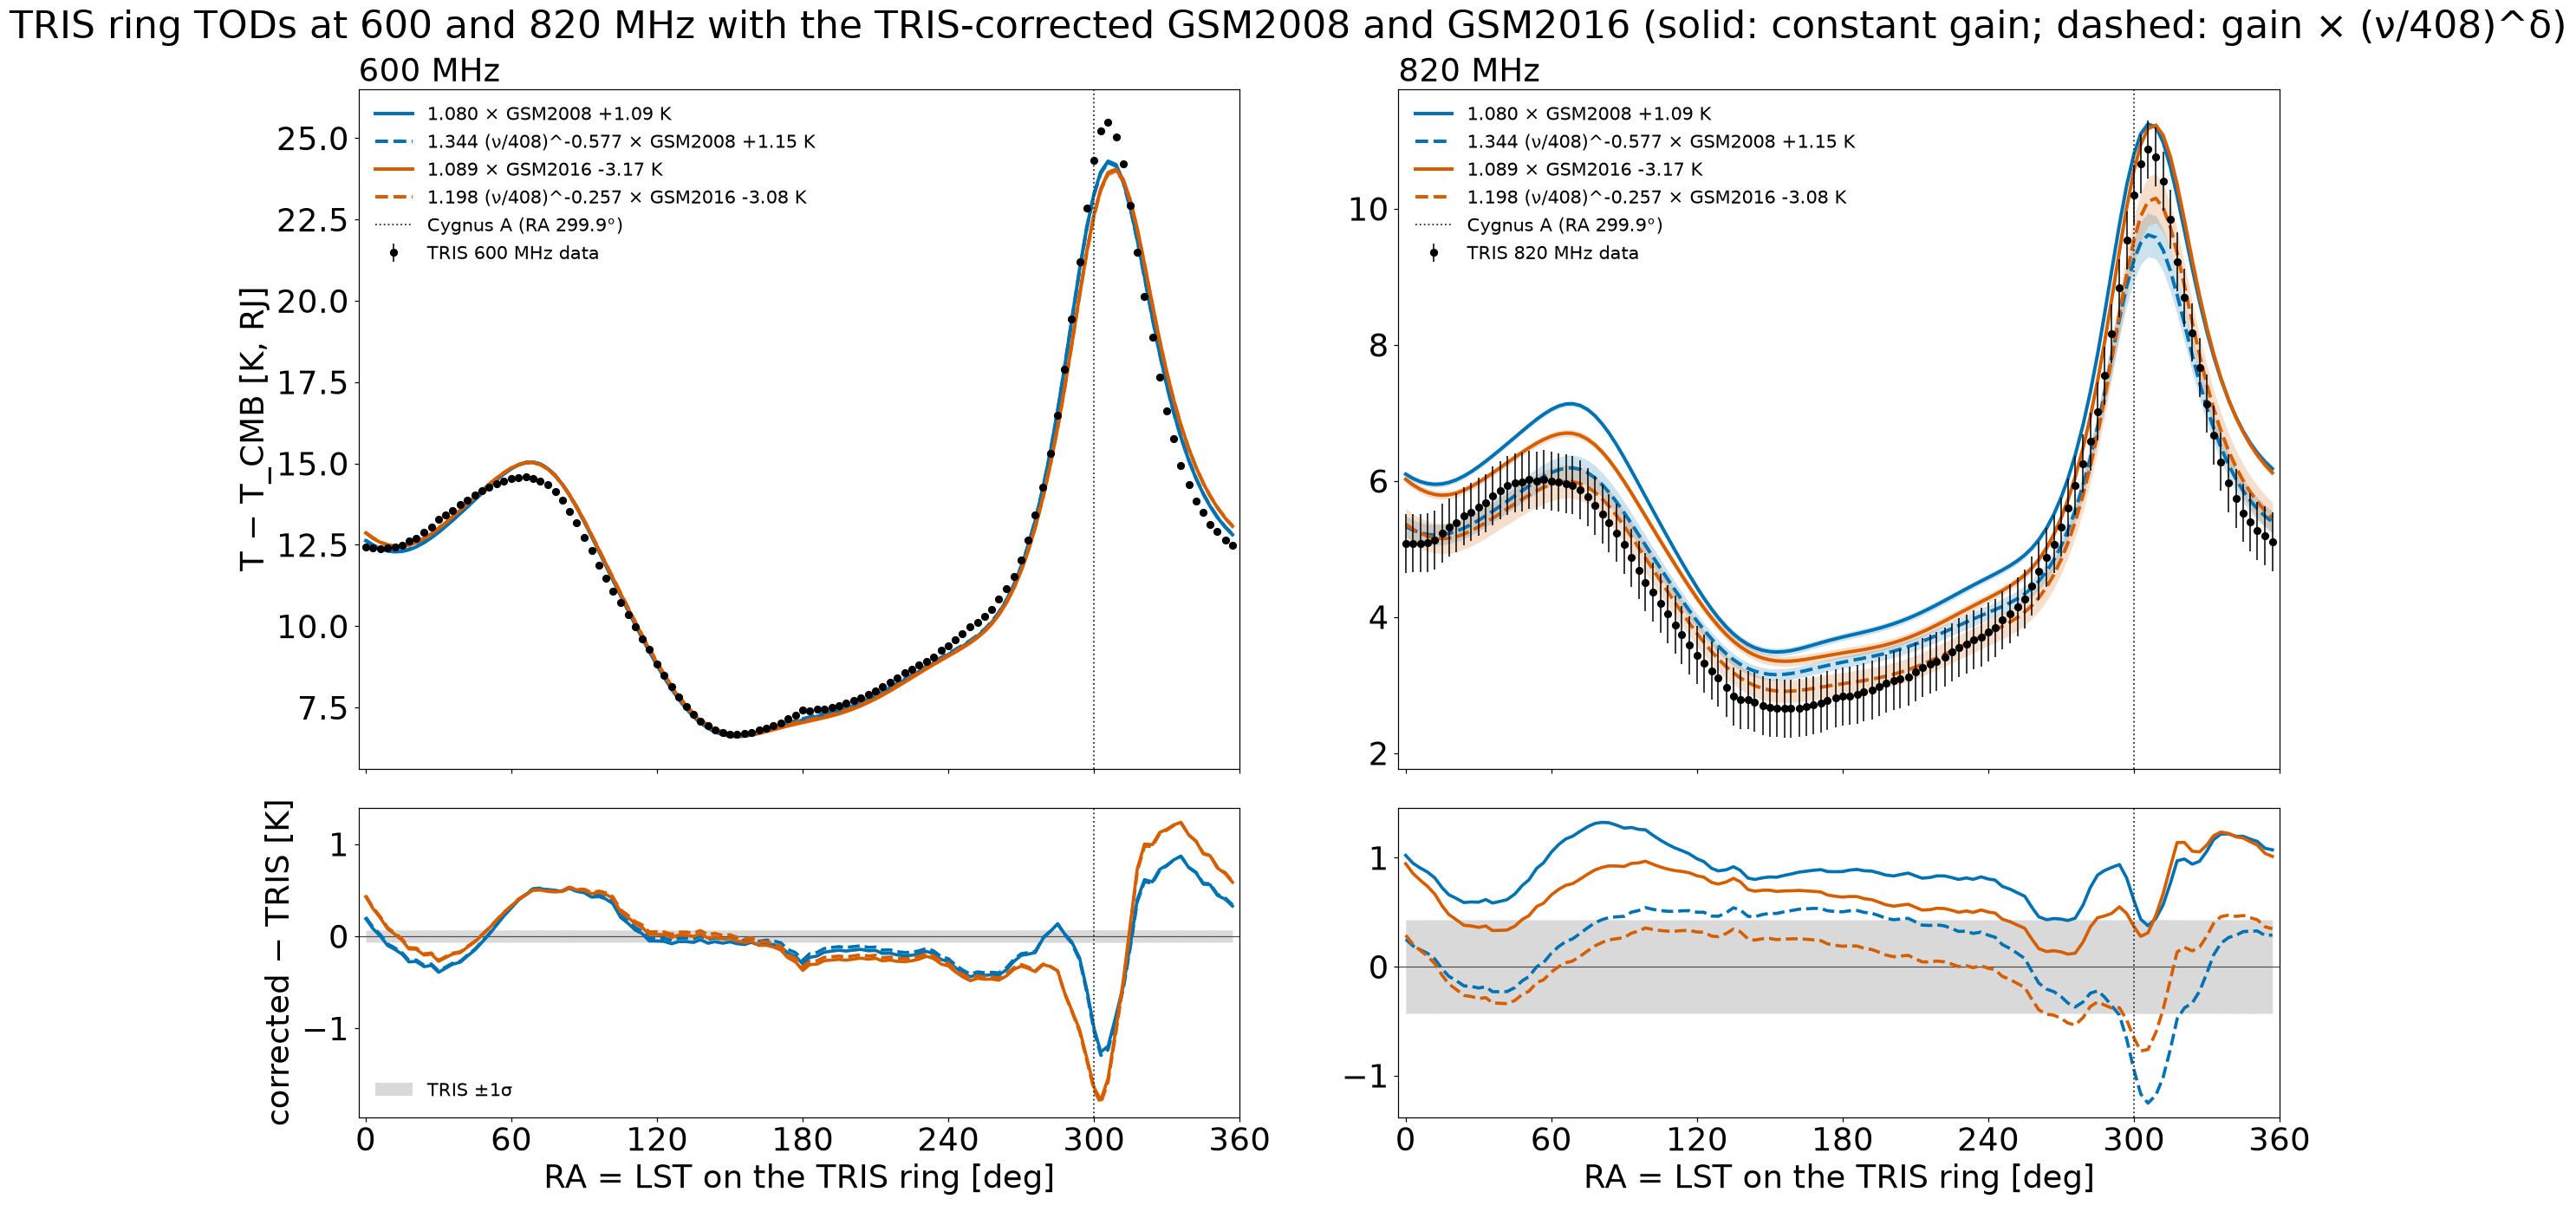

saved model_comparison/phil_plots/plot6d_corrected_gsm_vs_tris_tods.png
saved model_comparison/phil_plots/plot6d_corrected_gsm_minus_tris.csv

  model TRIS band               correction  median (model − TRIS) [K]  rms [K]   N
GSM2008 600.5 MHz                   before                     -1.763    1.990 120
GSM2008 600.5 MHz    after (constant gain)                     -0.084    0.385 120
GSM2008 600.5 MHz after (gain × (ν/408)^δ)                     -0.052    0.383 120
GSM2016 600.5 MHz                   before                      2.042    2.001 120
GSM2016 600.5 MHz    after (constant gain)                     -0.085    0.540 120
GSM2016 600.5 MHz after (gain × (ν/408)^δ)                     -0.057    0.540 120
GSM2008 817.8 MHz                   before                     -0.473    0.631 120
GSM2008 817.8 MHz    after (constant gain)                      0.868    0.905 120
GSM2008 817.8 MHz after (gain × (ν/408)^δ)                      0.289    0.435 120
GSM2016 817.8 MHz          

In [18]:
def corrected_tris(n, k, form=MAIN_FORM):
    # Plot 6b's correction at TRIS band k, with its 1 sigma from the fit's covariance.
    return corrected(n, form, T_GSM[(n, k)], NU_TRIS[k])

rows = []
fig, axes = plt.subplots(2, 2, figsize=(26, 14), sharex=True,
                         gridspec_kw=dict(height_ratios=[2.2, 1], hspace=0.08, wspace=0.18))
for c, k in enumerate(NU_TRIS):
    ax, ar = axes[0, c], axes[1, c]
    ax.errorbar(RA, T[k], yerr=S[k], fmt="o", ms=5, color="black", elinewidth=1, capsize=0,
                label=f"TRIS {k.split('_')[1]} MHz data", zorder=3)
    ar.fill_between(RA, -S[k], S[k], color="0.85", lw=0, label="TRIS ±1σ")
    ar.axhline(0, color="0.3", lw=0.8)
    for n in GSM_BASE:
        d = T_GSM[(n, k)] - T[k]
        rows.append({"model": n, "TRIS band": f"{NU_TRIS[k]:g} MHz", "correction": "before",
                     "median (model − TRIS) [K]": np.nanmedian(d), "rms [K]": np.sqrt(np.nanmean(d ** 2)),
                     "N": int(np.isfinite(d).sum())})
        for form in FORMS:
            pred, sig = corrected_tris(n, k, form)
            st = dict(color=GSM_COL[n], ls=FORM_LS[form])
            ax.fill_between(RA, pred - sig, pred + sig, color=GSM_COL[n], alpha=0.2, lw=0)
            ax.plot(RA, pred, lw=2.6, **st, label=form_label(n, form))
            ar.plot(RA, pred - T[k], lw=2.4, **st)
            d = pred - T[k]
            rows.append({"model": n, "TRIS band": f"{NU_TRIS[k]:g} MHz", "correction": f"after ({form})",
                         "median (model − TRIS) [K]": np.nanmedian(d), "rms [K]": np.sqrt(np.nanmean(d ** 2)),
                         "N": int(np.isfinite(d).sum())})
    for a in (ax, ar):
        a.axvline(299.9, color="0.2", ls=":", lw=1.2, label="Cygnus A (RA 299.9°)" if a is ax else None)
    ax.set_title(f"{k.split('_')[1]} MHz", loc="left")
    ax.legend(frameon=False, loc="upper left", fontsize=14)
    ar.set_xlabel("RA = LST on the TRIS ring [deg]")
    ar.set_xlim(-3, 360); ar.set_xticks(np.arange(0, 361, 60))
axes[0, 0].set_ylabel("T − T_CMB [K, RJ]")
axes[1, 0].set_ylabel("corrected − TRIS [K]")
axes[1, 0].legend(frameon=False, fontsize=14, loc="lower left")
fig.suptitle("TRIS ring TODs at 600 and 820 MHz with the TRIS-corrected GSM2008 and GSM2016 "
             "(solid: constant gain; dashed: gain × (ν/408)^δ)", y=0.94)
save(fig, "plot6d_corrected_gsm_vs_tris_tods")

cmp_tris = pd.DataFrame(rows)
cmp_tris.to_csv(OUT_DIR / "plot6d_corrected_gsm_minus_tris.csv", index=False)
print(f"saved {(OUT_DIR / 'plot6d_corrected_gsm_minus_tris.csv').relative_to(REPO)}\n")
with pd.option_context("display.width", 220):
    print(cmp_tris.round(3).to_string(index=False))

## 4. β implied by each sky model

* **Model 408 MHz vs TRIS data (all seven models):** the model's 408 MHz ring TOD (x, zero error)
  against the measured TRIS 600 and 820 MHz rings (y, with `ring_sigma`), fitted with `york`. With no
  x error this is a weighted fit in y, with σ inflated by √(χ²/ν) when χ²/ν > 1. It is the β between
  the model's 408 MHz sky and the measured TRIS sky.
* **The models' own β (GSM2008, GSM2016 only):** the model against itself at 408 → 600, 408 → 820 and
  600 → 820 MHz. Neither axis has an error, so this is an ordinary least-squares line
  (`np.polyfit(..., cov=True)`). Its error is from the residual scatter and has no χ²/ν.
* **The data's own β (reference row):** Haslam vs TRIS 600 and Haslam vs TRIS 820 (first two columns)
  and TRIS 600 vs TRIS 820 (last column), taken from Plot 4's fits. They include Haslam's error
  bars, so they differ slightly from the "Haslam (uncorrected)" model row, which has no x error.

A purely additive correction (Irfan's monopole) goes into the intercept, so it leaves β unchanged by
construction; Carter's 1.029 scale steepens β by ln(1.029) / ln(ν₂/408). The results are saved to
`plot5_model_implied_betas.csv`.

In [19]:
def ols_beta(x, y, nu1, nu2):
    ok = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
    (a, b), cov = np.polyfit(x[ok], y[ok], 1, cov=True)
    beta, err = slope_to_beta(dict(a=a, sa=np.sqrt(cov[0, 0])), nu1, nu2)
    return dict(a=a, sa=np.sqrt(cov[0, 0]), b=b, sb=np.sqrt(cov[1, 1]), chi2_dof=np.nan, beta=beta, err=err, n=int(ok.sum()))

def york_beta(x, sx, y, sy, nu1, nu2):
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(sx) & np.isfinite(sy) & (x > 0) & (y > 0)
    fit = york(x[ok], y[ok], sx[ok], sy[ok])
    beta, err = slope_to_beta(fit, nu1, nu2)
    return dict(**fit, beta=beta, err=err, n=int(ok.sum()))

COLS = ["408 model → TRIS 600 data", "408 model → TRIS 820 data",
        "408 → 600, model only", "408 → 820, model only", "600 → 820, model only"]
DATA_ROW = "data: Haslam 408, TRIS"
ROWS = [DATA_ROW] + MODELS
MB = {}                                          # (row, column) -> fit dict
zero = np.zeros(N)
for mname in MODELS:
    for c, k in zip(COLS[:2], NU_TRIS):
        MB[(mname, c)] = york_beta(T408[mname], zero, T[k], S[k], 408.0, NU_TRIS[k])
for g in GSM_REBUILT:
    k6, k8 = NU_TRIS
    MB[(g, COLS[2])] = ols_beta(T408[g], T_GSM[(g, k6)], 408.0, NU_TRIS[k6])
    MB[(g, COLS[3])] = ols_beta(T408[g], T_GSM[(g, k8)], 408.0, NU_TRIS[k8])
    MB[(g, COLS[4])] = ols_beta(T_GSM[(g, k6)], T_GSM[(g, k8)], NU_TRIS[k6], NU_TRIS[k8])
# Reference row: the data's own pairs (from Plot 4), placed in the columns they correspond to.
MB[(DATA_ROW, COLS[0])] = TT_OF[("Haslam 408", "TRIS 600")]
MB[(DATA_ROW, COLS[1])] = TT_OF[("Haslam 408", "TRIS 820")]
MB[(DATA_ROW, COLS[4])] = TT_OF[("TRIS 600", "TRIS 820")]

mb_df = pd.DataFrame([{"row": rw, "pair": c, "N samples": f["n"], "slope a": f["a"], "σ_a": f["sa"],
                       "intercept b [K]": f["b"], "χ²/ν": f["chi2_dof"], "β": f["beta"], "σ_β": f["err"]}
                      for (rw, c), f in MB.items()])
mb_df.to_csv(OUT_DIR / "plot5_model_implied_betas.csv", index=False)
print(f"saved {(OUT_DIR / 'plot5_model_implied_betas.csv').relative_to(REPO)}\n")
wide = mb_df.assign(cell=[f"{b:+.3f} ± {e:.3f}" for b, e in zip(mb_df["β"], mb_df["σ_β"])]) \
            .pivot(index="row", columns="pair", values="cell").reindex(index=ROWS, columns=COLS).fillna("—")
with pd.option_context("display.width", 250, "display.max_colwidth", 30):
    print(wide.to_string())

saved model_comparison/phil_plots/plot5_model_implied_betas.csv

pair                      408 model → TRIS 600 data 408 model → TRIS 820 data 408 → 600, model only 408 → 820, model only 600 → 820, model only
row                                                                                                                                            
data: Haslam 408, TRIS               -2.466 ± 0.097            -2.532 ± 0.062                     —                     —        -2.643 ± 0.063
Haslam (uncorrected)                 -2.435 ± 0.021            -2.528 ± 0.028                     —                     —                     —
Haslam, Carter correction            -2.509 ± 0.021            -2.569 ± 0.028                     —                     —                     —
Haslam, Irfan correction             -2.435 ± 0.021            -2.528 ± 0.028                     —                     —                     —
GSM2008                              -2.437 ± 0.021            -2.529 ±

### Plot 5 — β matrix: data pairs and model-implied β

In the style of notebook 08's Figure 13b. **Left:** β for every pair of surveys along the ring, from
Plot 4 (below the diagonal, β ± σ_β; above it, the pair's χ²/ν). **Right:** the β each sky model
implies. The first two columns, left of the dotted line, are the model's 408 MHz ring TOD against the
measured TRIS 600 and 820 MHz rings. The last three are GSM2008's and GSM2016's own β between their
408, 600 and 820 MHz ring TODs. The top row, above the solid line, is the data's own value in the
columns it corresponds to. Both panels share one colour scale (the 2nd–98th percentile of all the β
shown). No colour bar is drawn; every cell carries its value. **All β errors are underestimates**
(correlated ring samples).

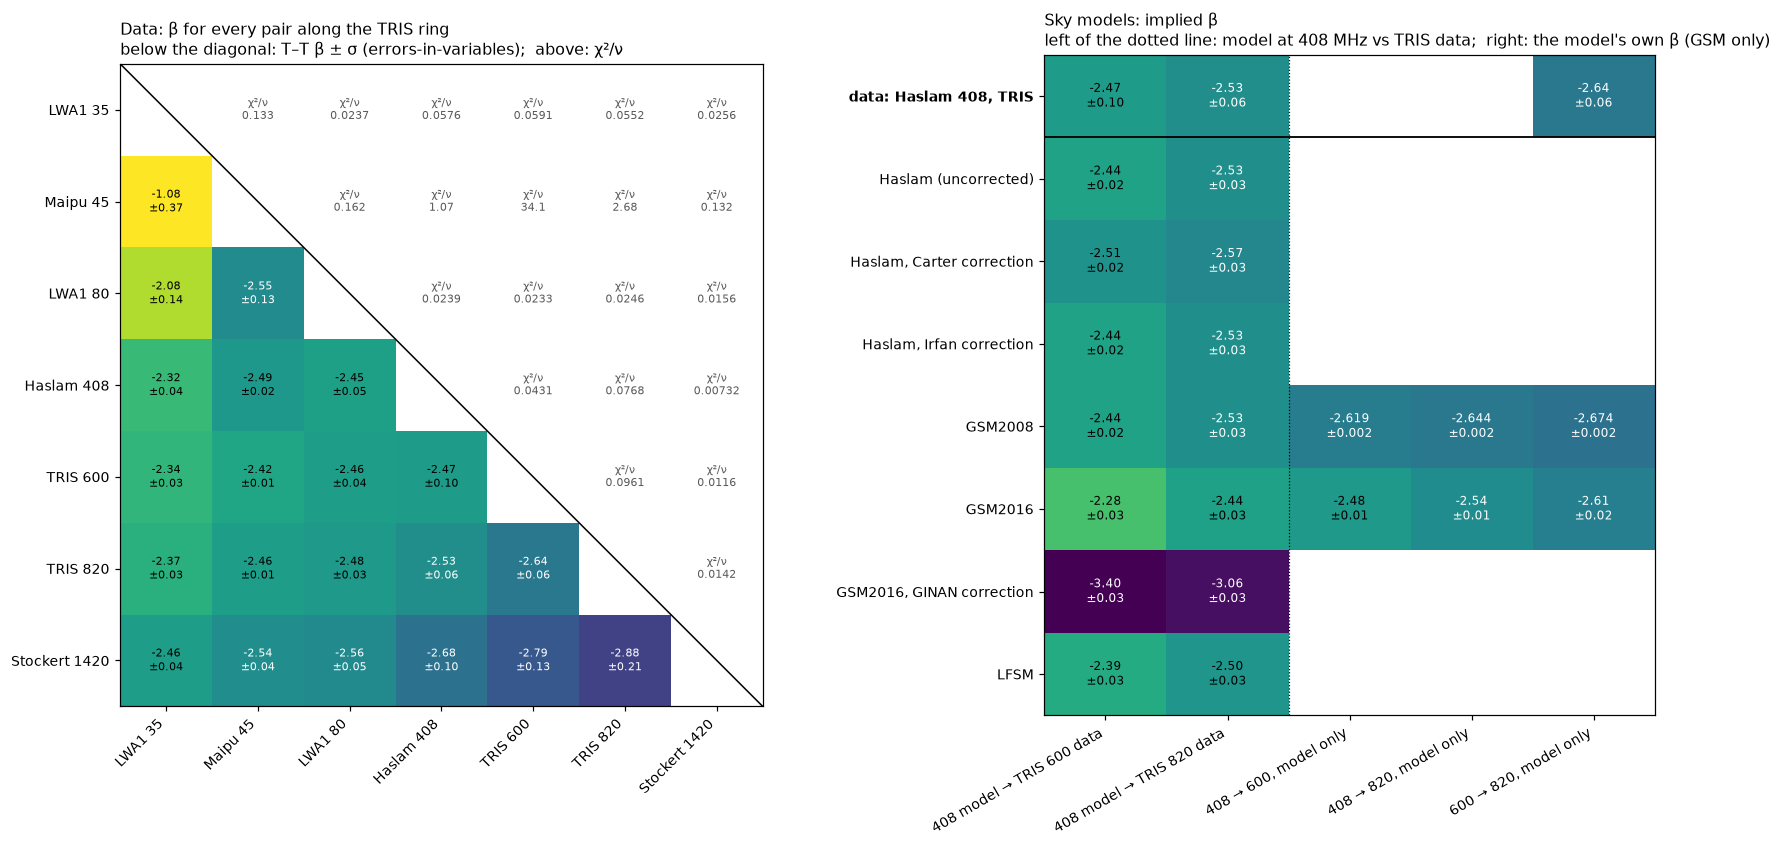

saved model_comparison/phil_plots/plot5_beta_matrix_data_vs_models.png


In [20]:
from matplotlib.colors import Normalize
NS = len(ORDER)
TT_M = np.full((NS, NS), np.nan); TT_E = np.full((NS, NS), np.nan); CHI = np.full((NS, NS), np.nan)
for i, lo in enumerate(ORDER):
    for j in range(i + 1, NS):
        r = TT_OF.get((lo, ORDER[j]))
        if r is not None:
            TT_M[j, i], TT_E[j, i], CHI[i, j] = r["beta"], r["err"], r["chi2_dof"]
MM = np.full((len(ROWS), len(COLS)), np.nan); ME = MM.copy()
for (rw, c), f in MB.items():
    MM[ROWS.index(rw), COLS.index(c)], ME[ROWS.index(rw), COLS.index(c)] = f["beta"], f["err"]

both = np.concatenate([TT_M[np.isfinite(TT_M)], MM[np.isfinite(MM)]])
lo_b, hi_b = np.percentile(both, [2, 98])
norm = Normalize(lo_b, hi_b)
cmap_b = plt.get_cmap("viridis").copy(); cmap_b.set_bad("white")
txt = lambda v: "white" if v < (lo_b + hi_b) / 2 else "black"

fig, (ax, axm) = plt.subplots(1, 2, figsize=(18, 7.8), gridspec_kw=dict(width_ratios=[1, 0.95], wspace=0.45))
im = ax.imshow(TT_M, cmap=cmap_b, norm=norm)
for i in range(NS):
    for j in range(NS):
        if i > j and np.isfinite(TT_M[i, j]):
            ax.text(j, i, f"{TT_M[i, j]:.2f}\n±{TT_E[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                    color=txt(TT_M[i, j]))
        elif i < j and np.isfinite(CHI[i, j]):
            ax.text(j, i, f"χ²/ν\n{CHI[i, j]:.3g}", ha="center", va="center", fontsize=7, color="0.35")
ax.plot([-0.5, NS - 0.5], [-0.5, NS - 0.5], color="k", lw=1)
ax.set_xticks(range(NS)); ax.set_yticks(range(NS))
ax.set_xticklabels(ORDER, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(ORDER, fontsize=9)
ax.set_title("Data: β for every pair along the TRIS ring\nbelow the diagonal: T–T β ± σ (errors-in-variables);  "
             "above: χ²/ν", loc="left", fontsize=10.5)

axm.imshow(MM, cmap=cmap_b, norm=norm, aspect="auto")
for i in range(len(ROWS)):
    for j in range(len(COLS)):
        if np.isfinite(MM[i, j]):
            axm.text(j, i, f"{MM[i, j]:.2f}\n±{ME[i, j]:.2f}" if ME[i, j] >= 0.005 else f"{MM[i, j]:.3f}\n±{ME[i, j]:.3f}", ha="center", va="center", fontsize=8,
                     color=txt(MM[i, j]))
axm.axhline(0.5, color="k", lw=1.2)
axm.axvline(1.5, color="k", lw=0.8, ls=":")
axm.set_xticks(range(len(COLS))); axm.set_yticks(range(len(ROWS)))
axm.set_xticklabels(COLS, rotation=30, ha="right", fontsize=9)
axm.set_yticklabels(ROWS, fontsize=9)
axm.get_yticklabels()[0].set_fontweight("bold")
axm.set_title("Sky models: implied β\nleft of the dotted line: model at 408 MHz vs TRIS data;  "
              "right: the model's own β (GSM only)", loc="left", fontsize=10.5)
# fig.colorbar(im, ax=[ax, axm], shrink=0.8, pad=0.02, label="β")
# fig.text(0.12, -0.12, "⚠ Ring samples are 3° apart under a ~20° beam, so they are correlated and every σ here is an "
#          "underestimate (by roughly ×2.6). CMB-removed RJ temperatures through the TRIS beam.", fontsize=10)
save(fig, "plot5_beta_matrix_data_vs_models")

## Summary

**Beam matching (2026-10-27).** Every survey TOD, Haslam and the sky models now come from notebook 18's beam-matched
TODs (`USE_BEAM_MATCHED = True`): the TRIS cut beam with each map's own beam taken out, on a 0.92° grid. Compared with the
earlier native-resolution limTOD TODs, every T–T β changed by 0.010 or less (well inside σ_β), so the numbers below
still hold to that precision.

Results from the run on 2026-10-27: 120 ring samples. σ is scaled by √(χ²/ν) where χ²/ν > 1 (all
`york` fits). **All σ_β are underestimates** (samples 3° apart under a ~20° beam; roughly ×2.6), so
read differences of a few σ as indicative only.

* **The data steepen with frequency (Plots 4, 4a).** β goes from −2.08 ± 0.14 for LWA1 35 vs LWA1 80
  (√(ν₁ν₂) ≈ 53 MHz) through −2.3 to −2.6 for the pairs between 120 and 600 MHz. It reaches −2.64 ± 0.06
  for TRIS 600 vs 820, then −2.80 ± 0.13 and −2.89 ± 0.21 for TRIS 600 and 820 vs Stockert. Only the
  pairs above ~900 MHz are steeper than −2.7. This is the curvature the curved power law fits.
* **LWA1 35 vs Maipu 45 (β = −1.09 ± 0.37) is not meaningful.** The two are only ×1.29 apart in
  frequency (notebook 08 drops such pairs), so a small scale mismatch becomes a large β.
* **Maipu 45 pairs are steeper than the LWA1 35 pairs at similar frequency (Plot 4a)**, by 0.08–0.16:
  vs Haslam −2.48 against −2.32, vs TRIS 600 −2.42 against −2.34, vs TRIS 820 −2.46 against −2.37, and
  vs Stockert −2.54 against −2.46.
* **Plot 4 shows two branches** in most pairs with Maipu or LWA1 35: the samples at RA ≈ 0–150° and
  RA ≈ 200–330° fall on different lines, so one slope over the whole ring averages two different
  spectra (or a beam/calibration difference between the surveys). The Maipu–TRIS 600 χ²/ν of 35 comes
  from this. Most other χ²/ν are ≪ 1 because the error bars are dominated by gain-scale terms.
* **Splitting the ring at RA = 200° (Plot 4b) changes β only modestly.**
  * LWA1 35 pairs are steeper for RA > 200°: by 0.09–0.12 against Haslam and TRIS (≈1.3σ) and by 0.34
    against LWA1 80 (1.1σ).
  * Stockert against Maipu, LWA1 80, Haslam and TRIS is flatter for RA > 200°, by 0.06–0.27, all within 1σ.
  * Maipu vs TRIS 600 and 820 are flatter for RA > 200° by 0.08 and 0.07. These are the only
    differences above 2σ (3.3σ and 2.7σ).
  * The other pairs agree between the halves to within 0.08, all under 0.5σ. LWA1 35 vs Maipu 45
    (−0.68 and −2.12) is again not meaningful.
* **Model 408 MHz → TRIS data.** Uncorrected Haslam, GSM2008 and the Irfan correction give the same β
  (−2.44 to 600, −2.53 to 820); Irfan's correction is a pure offset, so it cannot change β. Carter's
  scale steepens it to −2.52 / −2.57. GSM2016 (−2.27 / −2.44) and LFSM (−2.35 / −2.48) are flatter.
  The GINAN-corrected GSM2016 is far off (−3.39 / −3.06): its 1.53× scale exaggerates the ring's
  contrast at 408 MHz, as notebook 12 found.
* **The models' own β (408 → 600 → 820).** GSM2016 matches the data's own β closely: −2.48 vs −2.47
  (408 → 600), −2.54 vs −2.54 (408 → 820), −2.61 vs −2.64 (600 → 820). GSM2008 is steeper on every pair
  (−2.62, −2.64, −2.67). So GSM2016 has the right spectral slope between 408 and 820 MHz along the
  ring, while GSM2008 falls too fast.
* **Caveats.** All the sky models use Haslam at 408 MHz, so they are not independent of the Haslam
  row. The GSM maps were made at the TRIS effective frequencies (600.5, 817.8 MHz), not 600/820.
  The model-only β have no data errors, so their σ is just the scatter about a line.

**Plots 6a–6c (TRIS-calibrated models, 2026-10-27).** σ below are underestimates (correlated samples; common TRIS zero
level treated as independent).

* **6a:** after a scale and offset per frequency, every model fits TRIS to an rms of 0.38–0.63 K at 600 MHz and
  0.23–0.33 K at 820 MHz. GSM2008 (with or without Carter) is best at both (0.38 K, 0.23 K). The fitted scale is
  ≈ 1.07–1.08 for GSM2008 and GSM2016 at both frequencies; GSM2016's offset is ≈ −3.1 to −3.7 K, GSM2008's +1.2 / +0.2 K.
  The remaining structure is common to all models (≈ ±0.5 K at 600 MHz, up to +2 K near Cygnus A).
* **6b, suggested correction (one gain, constant offset):** GSM2008 → 1.080 × GSM2008 + 1.09 K; GSM2016 → 1.089 ×
  GSM2016 − 3.17 K (g and z correlated, ρ ≈ −0.92 to −0.96). That the offset is constant in frequency is an assumption:
  two frequencies cannot measure how it scales.
* **6b with a power law in frequency on the gain,** g (ν/408)^δ T_GSM + z (2026-10-28): the fit gives δ = −0.58 ± 0.12
  (GSM2008) and −0.26 ± 0.09 (GSM2016), not a weak factor. It mostly stands in for an offset that differs between the
  two rings: Plot 6a's per-frequency scales alone give δ = +0.03 ± 0.07 and −0.04 ± 0.07, consistent with zero. It
  improves 820 MHz (rms 0.91 → 0.43 K, 0.71 → 0.30 K) and leaves 600 MHz unchanged, but carried to 408 MHz its gain is
  1.34 / 1.20, and the predicted 408 MHz TOD is 3–8 K above the constant-gain one.
* **6c, the predicted 408 MHz TOD against Haslam:** from corrected GSM2016, Haslam + Carter agrees
  best (median +0.15 K, rms 0.82 K); uncorrected Haslam is −1.42 K (rms 1.78), Irfan −7.6 K. From corrected GSM2008 every
  Haslam version is lower (Carter −1.65, uncorrected −3.40, Irfan −9.58 K). With the gain × (ν/408)^δ form every Haslam version is much lower still (from GSM2016: Carter −2.94, uncorrected −4.84 K; from GSM2008: Carter −9.35 K), because that form's 408 MHz gain comes from extrapolating δ.
